# Analysis

Vier Teile der Analysis, durchgerechnet mit numpy, scipy, sympy und mpmath: die komplexe Analysis von Phasenbildern und Residuen bis zu Zerfallsraten und Lee-Yang-Nullstellen; die Fourier-Analyse von Gibbs und Parseval über FFT und Abtasttheorem bis zur Periodenfindung in Shors Algorithmus; die Funktionalanalysis mit Spektren, unbeschränkten Operatoren, dem Koopman-Operator und Operator-Lernen; und Testfunktionen in beiden Bedeutungen, glatte Funktionen mit kompaktem Träger und Benchmark-Funktionen der Optimierung, bis zu Phasenschätzung, adiabatischen Zeitplänen und Barren Plateaus. Daten werden nicht geladen. Der Code steht in [`code/analysis/`](https://github.com/deltorobarba/science/tree/main/code/analysis), ein Modul je Teil (`complexanalysis.py`, `fourier.py`, `functional.py`, `testfunctions.py`); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Die vier Teile fragen, was eine Funktion über sich verrät, wenn man sie anders darstellt.

- **Schritte 1 bis 15, komplexe Analysis:** Wer im Komplexen differenzierbar ist, wird von seinen Singularitäten bestimmt. Pole und Verzweigungen entscheiden über Konvergenzradien, Integrale, Stabilität und Lebensdauern.
- **Schritte 16 bis 31, Fourier-Analyse:** In Frequenzen zerlegt, werden Ableiten und Glätten zu Multiplizieren. Glattheit zeigt sich am Abfall der Koeffizienten, und Ort und Frequenz lassen sich nicht zugleich schärfen.
- **Schritte 32 bis 47, Funktionalanalysis:** lineare Algebra in unendlich vielen Dimensionen. Spektren kommen ohne Eigenwerte aus, Operatoren können unbeschränkt sein; das braucht die Quantenmechanik, und das Lernen von Operatoren baut darauf auf.
- **Schritte 48 bis 65, Testfunktionen:** Was man nicht direkt fassen kann, prüft man an etwas Bekanntem, mit glatten Funktionen in der Analysis und mit bekannten Minima in der Optimierung. Beide tauchen in Quantenalgorithmen wieder auf.

Die gemeinsame Lehre: Glattheit und Singularitäten bestimmen das Verhalten. Wo eine Funktion einen Knick, einen Sprung oder einen Pol hat, konvergieren Reihen langsam oder gar nicht, fallen Fourier-Koeffizienten langsam und werden die Fehler adiabatischer Zeitpläne groß; wer weiß, wo die Singularität liegt, weiß, was zu erwarten ist.

In [1]:
import sys
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "analysis"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["complexanalysis.py", "fourier.py", "functional.py", "testfunctions.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/analysis/{f}", CODE / f)
if "google.colab" not in sys.modules and (importlib.util.find_spec("mpmath") is None or importlib.util.find_spec("sympy") is None):
    raise ImportError("Es fehlt eines der Pakete mpmath, sympy; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import complexanalysis, fourier, functional, testfunctions

**1. Komplexe Analysis: Zahlen als Drehstreckungen**

Im Reellen ist Differenzierbarkeit eine schwache Eigenschaft, im Komplexen eine sehr starke: Eine komplex differenzierbare (holomorphe) Funktion ist beliebig oft differenzierbar, wird lokal durch eine Potenzreihe dargestellt, und ihre Werte im Inneren eines Gebiets sind durch die Werte auf dem Rand festgelegt. Ihr Verhalten bestimmen ihre Singularitäten. Cauchy fand 1825 den Integralsatz und die Residuen, Riemann brachte 1851 die geometrische Sicht; heute rechnen damit Strömungslehre, Regelungstechnik, Optik und Quantenmechanik. Zuerst die Zahlen selbst: Multiplikation mit w dreht und streckt, die Lösungen von zⁿ = 1 liegen auf einem Kreis, und Amplituden interferieren.

Ein Haus, zwölfmal mit w multipliziert, dreht sich pro Schritt um 30° und wächst um den Faktor 1.15; nach zwölf Schritten ist es einmal herum und 5.4-mal so groß. Die sieben Lösungen von z⁷ = 1 bilden ein regelmäßiges Siebeneck, ihre Summe ist null. Bei zwei Wegen mit je Wahrscheinlichkeit 1/2 ergibt die Summe der Amplituden je nach Phasendifferenz zwischen 0 und 2: das Doppelspaltexperiment in einer Zeile.

Multiplikation als Matrix: True | e^(iπ) + 1 = 0.0e+00+1.2e-16j
Summe der 7. Einheitswurzeln: 1.6e-16 | Produkt: (1-0j)


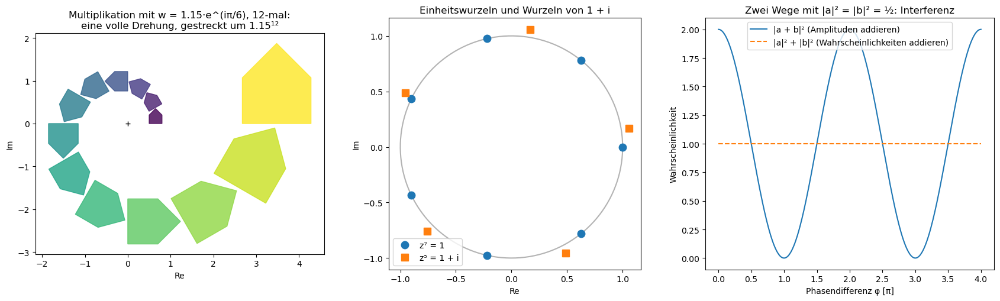

In [2]:
complexanalysis.complex_numbers()

**2. Phasenbilder: Nullstellen und Pole sehen**

Ein Phasenbild färbt jeden Punkt z nach dem Argument von f(z), die Helligkeit zeigt den Betrag. Nullstellen und Pole erkennt man daran, dass die Farben um sie herumlaufen.

Bei z laufen die Farben einmal gegen den Uhrzeigersinn herum, bei z³ dreimal, bei 1/z einmal in umgekehrter Richtung: ein Pol. Bei einer rationalen Funktion gibt die Umlaufzahl kleiner Kreise die Ordnung an: +1, +1 und +2 für die Nullstellen, −1 für die beiden Pole. e^z hat weder Nullstellen noch Pole; seine Farben bilden waagrechte Bänder mit der Periode 2π.

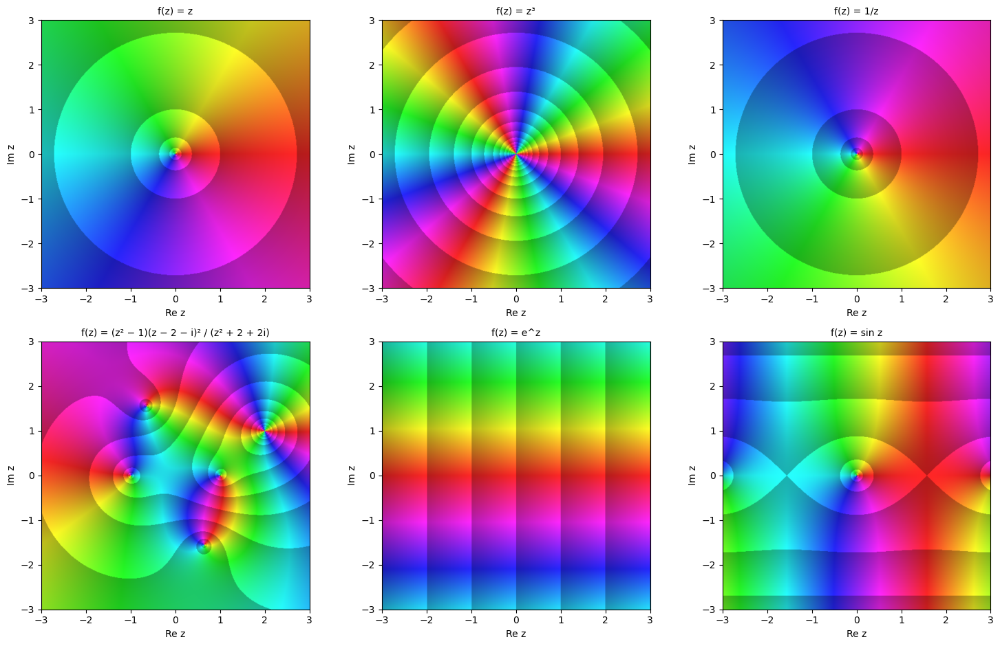

Nullstelle 1   bei 1.000+0.000j: Umlaufzahl des Bildes eines kleinen Kreises +1
Nullstelle −1  bei -1.000+0.000j: Umlaufzahl des Bildes eines kleinen Kreises +1
Nullstelle 2+i bei 2.000+1.000j: Umlaufzahl des Bildes eines kleinen Kreises +2
Pol            bei 0.644-1.554j: Umlaufzahl des Bildes eines kleinen Kreises -1
Pol            bei -0.644+1.554j: Umlaufzahl des Bildes eines kleinen Kreises -1


In [3]:
complexanalysis.phase_portraits()

**3. Holomorphie: Cauchy-Riemann, Winkeltreue und Strömungen**

Komplex differenzierbar heißt: Real- und Imaginärteil erfüllen die Cauchy-Riemann-Gleichungen. Solche Abbildungen erhalten Winkel; damit berechnet man die Strömung um ein Tragflächenprofil (Joukowski).

z², e^z, sin z und 1/z erfüllen die Gleichungen bis auf den Fehler der numerischen Ableitung (10⁻⁹); z̄, |z|² und Re z verletzen sie, weil sie von z̄ abhängen. Unter z² werden Gitterlinien zu Parabeln, die sich weiter unter 90° schneiden; nur bei z = 0, wo f′ = 0 ist, verdoppelt sich der Winkel. Am Profil fließt die Luft an der Hinterkante glatt ab (Kutta-Bedingung); die Zirkulation Γ = 2.88 macht die Strömung oben schneller als unten, und daraus folgt der Auftrieb ρUΓ.

z²    : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 5.6e-10
e^z   : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 1.0e-09
sin z : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 4.4e-10
1/z   : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 2.2e-10
z̄    : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 2.0e+00
|z|²  : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 4.5e+00
Re z  : größter Cauchy-Riemann-Rest an 20 Zufallspunkten 1.0e+00
Winkel der Bildkurven unter z²: [90.     90.0001 90.     90.     90.    ] Grad; bei z = 0: 180 Grad (z² verdoppelt Winkel, f'(0) = 0)
Zirkulation nach der Kutta-Bedingung Γ = 2.8843, Auftrieb pro Länge ρUΓ = 2.8843·ρU² (Kutta–Joukowski)


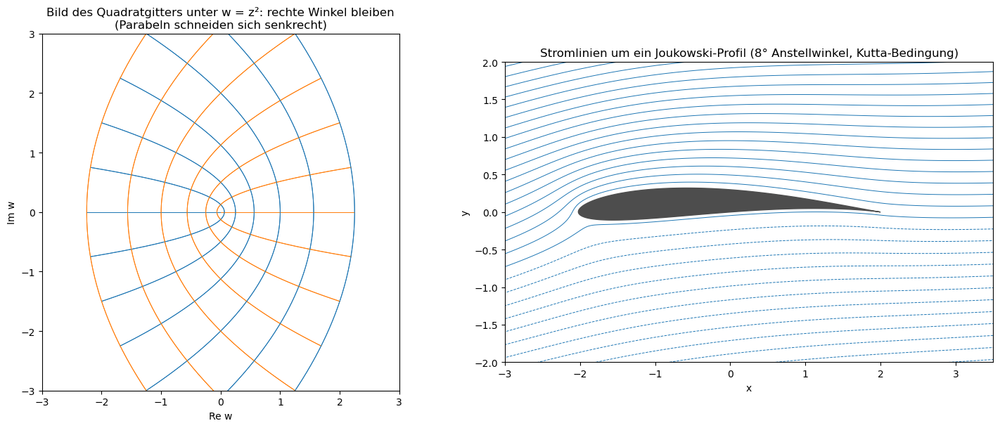

In [4]:
complexanalysis.holomorphy()

**4. Cauchy-Satz, Integralformel und die Trapezregel**

Das Integral einer holomorphen Funktion über einen geschlossenen Weg ist null; liegt ein Pol innen, bleibt 2πi mal sein Residuum. Die Integralformel gibt alle Ableitungen aus den Werten auf einem Kreis, und die Trapezregel konvergiert dort exponentiell schnell.

e^z und z² ergeben 0, 1/z ergibt 2πi, 1/z² trotz Pol 0, weil sein Residuum null ist; das nicht holomorphe z̄ gibt 2i mal die Fläche des Kreises. Für den holomorphen Integranden erreicht die Trapezregel mit etwa 18 Punkten Maschinengenauigkeit, für |sin θ|³ fällt der Fehler nur wie N⁻⁴. Die Taylor-Koeffizienten von e^z aus einer FFT auf dem Kreis stimmen bis n = 30 auf 4·10⁻¹⁰.

∮ e^z, Kreis um 0.3+0.2i   = -0.000000-0.000000j   (erwartet 0.000000)
∮ z², Kreis um 0.3+0.2i    = 0.000000-0.000000j   (erwartet 0.000000)
∮ 1/z, 0 innen             = 0.000000+6.283185j   (erwartet 0.000000+6.283185j)
∮ 1/z², 0 innen            = 0.000000-0.000000j   (erwartet 0.000000)
∮ z̄ (nicht holomorph)     = 0.000000+1.570796j   (erwartet 0.000000+1.570796j)
Taylor-Koeffizienten von e^z aus der Cauchy-Formel (FFT, 128 Punkte), n!·c_n für n = 0..7: [1. 1. 1. 1. 1. 1. 1. 1.]
größter relativer Fehler |n!·c_n − 1| für n ≤ 30: 4.2e-10


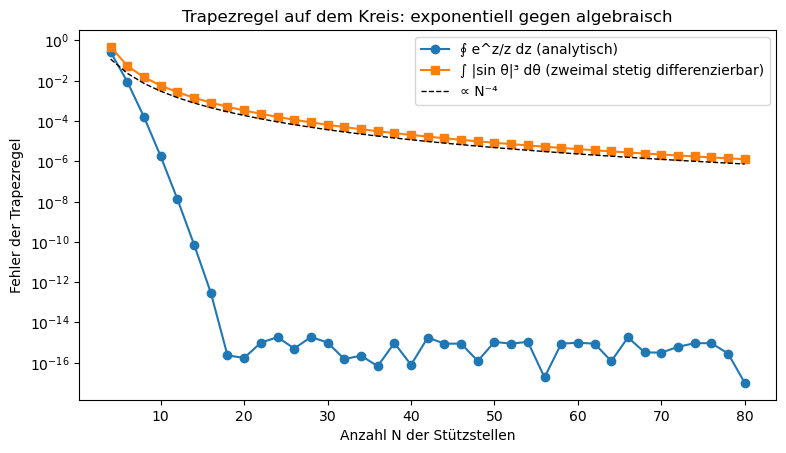

In [5]:
complexanalysis.cauchy()

**5. Der Konvergenzradius: die Singularität, die man auf der reellen Achse nicht sieht**

Die Taylor-Reihe von 1/(1 + x²) konvergiert nur für |x| < 1, obwohl die Funktion auf der reellen Achse überall glatt ist. Den Grund zeigt die komplexe Ebene.

Außerhalb von |x| < 1 laufen die Taylor-Polynome davon, und höhere Grade machen es schlimmer. Die Funktion hat Pole bei ±i, genau auf dem Einheitskreis, und die Kreisscheibe der Konvergenz kann nicht über sie hinauswachsen. Die Schätzung |c_n|^(−1/n) trifft für fünf Funktionen den Abstand zur nächsten Singularität; bei log(1 + z) nähert sie sich nur langsam (1.07 bei n = 60). So verrät der Konvergenzradius jeder Reihe die nächste Singularität in der komplexen Ebene.

1/(1+z²)   : Schätzung bei n = 60: 1.000, Abstand zur nächsten Singularität 1.000
1/(4+z²)   : Schätzung bei n = 60: 2.000, Abstand zur nächsten Singularität 2.000
log(1+z)   : Schätzung bei n = 60: 1.070, Abstand zur nächsten Singularität 1.000
tan z      : Schätzung bei n = 60: 1.530, Abstand zur nächsten Singularität 1.571
1/(1−z+z²) : Schätzung bei n = 60: 1.000, Abstand zur nächsten Singularität 1.000


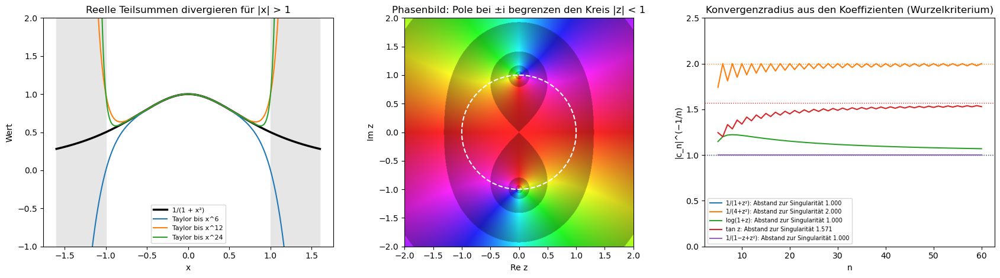

In [6]:
complexanalysis.convergence_radius()

**6. Isolierte Singularitäten: hebbar, Pol, wesentlich**

Drei Arten, wie eine Funktion an einem Punkt nicht definiert sein kann: sin z/z, 1/z³ und e^(1/z). Unterscheiden lassen sie sich an der Laurent-Reihe, der Potenzreihe mit negativen Potenzen.

sin z/z hat keine negativen Potenzen: Die Singularität ist hebbar, im Phasenbild sieht man nichts. 1/z³ hat genau eine, die Farben laufen dreimal herum: ein Pol der Ordnung 3, der Betrag wächst wie r⁻³. e^(1/z) hat unendlich viele, mit den Koeffizienten 1/n!. Auf jedem kleinen Kreis um 0 wird sie riesig und winzig, und sie nimmt dort fast jeden Wert an: Die Lösungen von e^(1/z) = 2 − 3i drängen sich zum Ursprung.

hebbar: sin z / z        : |c_n| für n = −6..2: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.1667]


Pol der Ordnung 3: 1/z³  : |c_n| für n = −6..2: [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
wesentlich: e^(1/z)      : |c_n| für n = −6..2: [0.0014, 0.0083, 0.0417, 0.1667, 0.5, 1.0, 1.0, 0.0, 0.0]
zum Vergleich 1/n! für n = 6..0: [0.0014, 0.0083, 0.0417, 0.1667, 0.5, 1.0, 1.0]


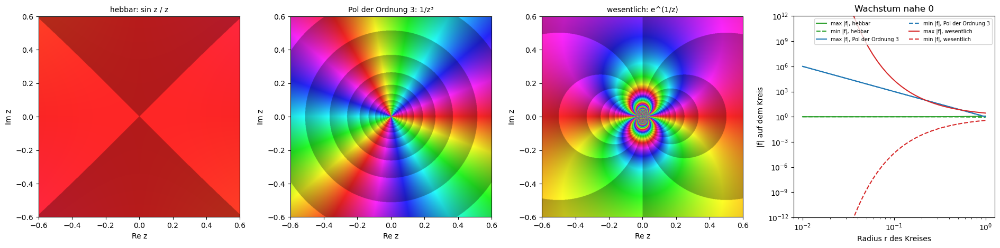

Lösungen von e^(1/z) = (2-3j): |z_k| = [0.1834 0.0858 0.0558 0.0413 0.0328], Probe |e^(1/z_k) − w| = 1.8e-14


In [7]:
complexanalysis.singularities()

**7. Verzweigungspunkte und Riemann-Flächen**

√z und log z sind nicht eindeutig: Läuft man einmal um den Ursprung, kommt man bei einem anderen Wert an. Riemann machte daraus Flächen mit mehreren Blättern.

Nach einem Umlauf ist √2 zu −√2 geworden, nach zwei Umläufen wieder √2: Die Riemann-Fläche von √z hat zwei Blätter. log z gewinnt pro Umlauf 2πi und kehrt nie zurück; seine Fläche ist eine unendliche Wendeltreppe. Der Hauptzweig von √z springt an der negativen reellen Achse, dem Schnitt, und nimmt nur die halbe Ebene an.

nach 1 Umlauf/Umläufen: √z = -1.4142+0.0000j (Start 1.4142+0.0000j), log z = 0.6931+6.2832j (Start 0.6931+0.0000j)
nach 2 Umlauf/Umläufen: √z = 1.4142-0.0000j (Start 1.4142+0.0000j), log z = 0.6931+12.5664j (Start 0.6931+0.0000j)


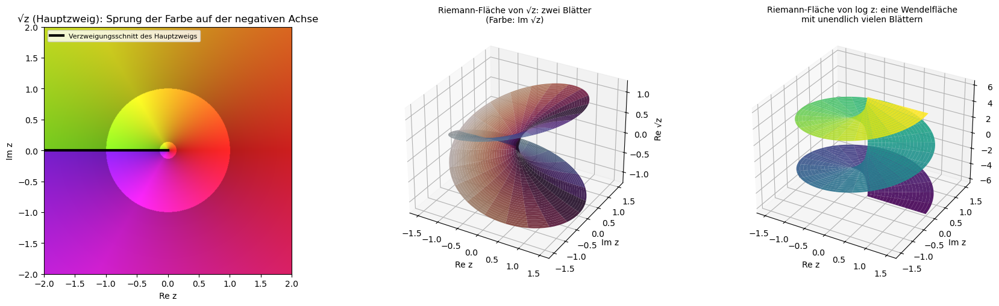

In [8]:
complexanalysis.branch_points()

**8. Der Residuensatz für reelle Integrale**

Viele reelle Integrale berechnet man, indem man den Weg in der komplexen Ebene schließt und die Residuen der eingeschlossenen Pole summiert. Sechs Beispiele mit Halbkreis, Einbuchtung, Schlüsselloch und Einheitskreis.

Für ∫ cos 2x/(1 + x²) umschließt der Halbkreis den Pol bei i. Strecke und Bogen schwingen einzeln, ihre Summe ist für jeden Radius über 1 gleich πe⁻² = 0.4252, und der Bogen verschwindet für großen Radius. Alle sechs Integrale stimmen mit der numerischen Integration auf 5·10⁻¹¹ oder besser überein, darunter ∫ sin x/x = π/2 und π/sin(0.3π) = 3.883.

∫ dx/(1+x²) über ℝ                     numerisch 3.1415926536, Residuen 3.1415926536, Differenz 0.0e+00  (Halbkreis, Pol i: 2πi·1/(2i))
∫ dx/(1+x⁴) über ℝ                     numerisch 2.2214414691, Residuen 2.2214414691, Differenz 4.4e-16  (Halbkreis, Pole e^(iπ/4), e^(3iπ/4))
∫ cos(2x)/(1+x²) über ℝ                numerisch 0.4251683316, Residuen 0.4251683316, Differenz 1.7e-11  (Halbkreis mit e^(2iz), Jordan)
∫ sin x / x über [0, ∞)                numerisch 1.5707963268, Residuen 1.5707963268, Differenz 5.2e-11  (Halbkreis mit Einbuchtung um 0)
∫ x^(a−1)/(1+x) über [0, ∞), a = 0.3   numerisch 3.8832220775, Residuen 3.8832220775, Differenz 4.4e-14  (Schlüsselloch um den Schnitt)
∫ dθ/(2 + cos θ) über [0, 2π]          numerisch 3.6275987285, Residuen 3.6275987285, Differenz 4.4e-16  (Einheitskreis z = e^(iθ))
Residuum von e^(2iz)/(1+z²) bei i, numerisch über einen kleinen Kreis: -0.00000000-0.06766764j, Formel e^(−2)/(2i) = 0.00000000-0.06766764j


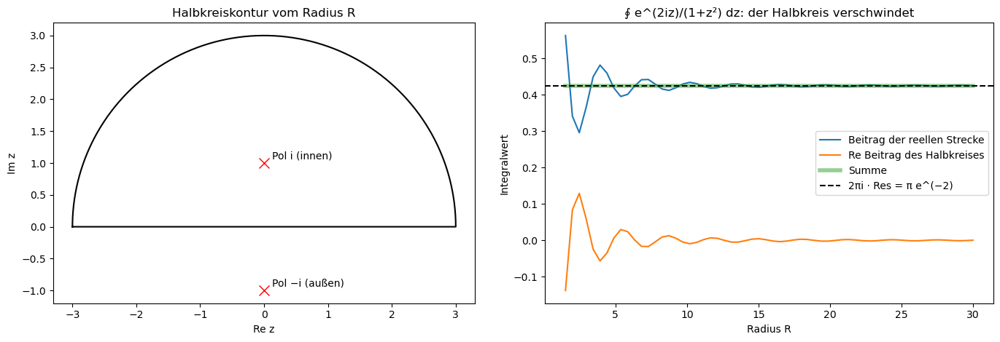

In [9]:
complexanalysis.residues()

**9. Argumentprinzip, Rouché und das Nyquist-Kriterium**

Wie oft das Bild eines Kreises unter f um den Ursprung läuft, zählt die Nullstellen minus die Pole im Inneren. Dasselbe Prinzip entscheidet in der Regelungstechnik, ob ein geschlossener Regelkreis stabil ist.

Für ein Polynom fünften Grades ergeben die Umlaufzahlen 0, 2, 3, 3 und 5 für wachsende Radien, genau die Zahl der Nullstellen im Inneren. Die Nyquist-Kurve des Regelkreises bleibt bei der Verstärkung K = 4 rechts von −1, der Kreis ist stabil. Bei K = 8 geht sie genau durch −1 und der Kreis schwingt ungedämpft; bei K = 12 umläuft sie −1 zweimal, und zwei Pole sind instabil.

|z| < 0.3: Umlaufzahl +0, Nullstellen laut np.roots: 0
|z| < 0.6: Umlaufzahl +2, Nullstellen laut np.roots: 2
|z| < 1.0: Umlaufzahl +3, Nullstellen laut np.roots: 3
|z| < 1.5: Umlaufzahl +3, Nullstellen laut np.roots: 3
|z| < 2.0: Umlaufzahl +5, Nullstellen laut np.roots: 5


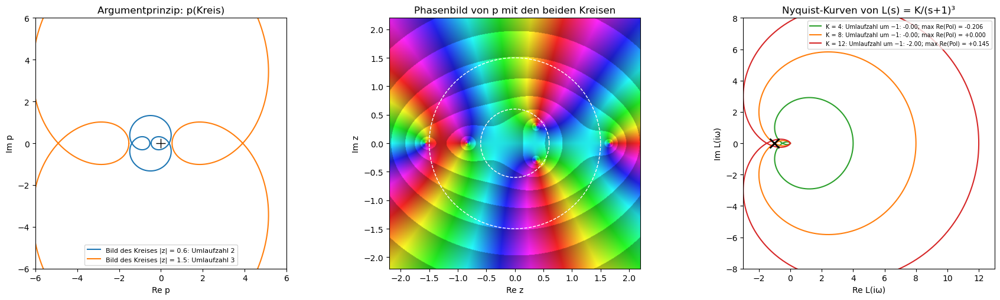

kritisch: L(iω) reell negativ bei 3·arctan ω = π, also ω = √3 und |L| = K/8: K_krit = 8


In [10]:
complexanalysis.argument_principle()

**10. Laplace-Transformation: Pole, Residuen und die Talbot-Kontur**

Die Laplace-Transformation macht aus einer Differentialgleichung eine rationale Funktion. Die Lage ihrer Pole bestimmt das Verhalten in der Zeit, und die Rücktransformation ist eine Summe von Residuen. Ein gedämpfter Oszillator mit drei Dämpfungen, dazu die Wärmeleitung über die Talbot-Kontur.

Schwache Dämpfung legt ein Polpaar nahe an die imaginäre Achse (−0.2 ± 0.98i): Die Antwort schießt auf etwa 1.5 über und klingt langsam ab. Bei kritischer Dämpfung fallen beide Pole bei −1 zusammen, und die Antwort erreicht den Endwert am schnellsten ohne Überschwingen; bei Überdämpfung bestimmt der langsame Pol −0.268 das Kriechen. Residuensumme und numerische Lösung stimmen auf 5·10⁻¹¹ überein, die Talbot-Kontur trifft erfc auf 4·10⁻¹³.

schwach gedämpft, γ = 0.2 : Pole [-0.2-0.98j -0.2+0.98j  0. +0.j  ], größte Abweichung Residuen − ODE 5.0e-11
kritisch, γ = 1           : Pole [-1.  0.], größte Abweichung Residuen − ODE 1.0e-11
überdämpft, γ = 2         : Pole [-3.732 -0.268  0.   ], größte Abweichung Residuen − ODE 1.7e-11


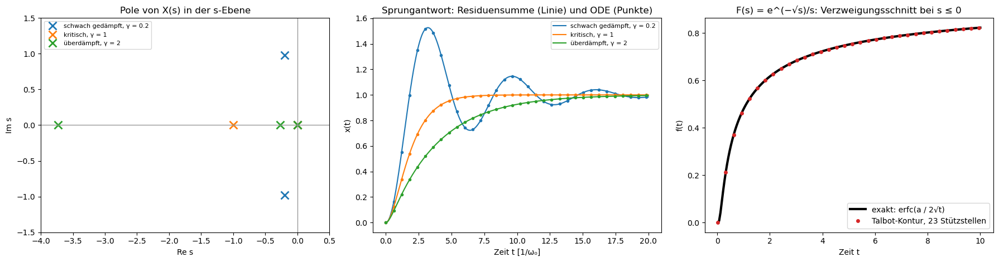

Talbot gegen erfc: größte Abweichung 4.3e-13


In [11]:
complexanalysis.laplace()

**11. Kramers-Kronig: Kausalität verbindet Real- und Imaginärteil**

Eine Antwortfunktion, die nicht vor ihrer Ursache reagiert, hat alle Pole in der unteren Halbebene. Daraus folgt: Der Realteil (Dispersion) ist durch den Imaginärteil (Absorption) festgelegt.

Der aus dem Imaginärteil rekonstruierte Realteil liegt auf der exakten Kurve, mit der typischen Dispersionsform um die Resonanz (Abweichung 8·10⁻⁹). Im Zeitbereich ist die Antwort vor dem Stoß null und danach eine gedämpfte Schwingung. Beides hat denselben Grund: Die Pole liegen bei ±0.989 − 0.15i, in der unteren Halbebene.

Pole von χ: [ 0.9887-0.15j -0.9887-0.15j] (beide mit Im < 0)
größte Abweichung Re χ (Kramers–Kronig) − Re χ (exakt): 8.0e-09 (Rest vom endlichen Integrationsbereich)


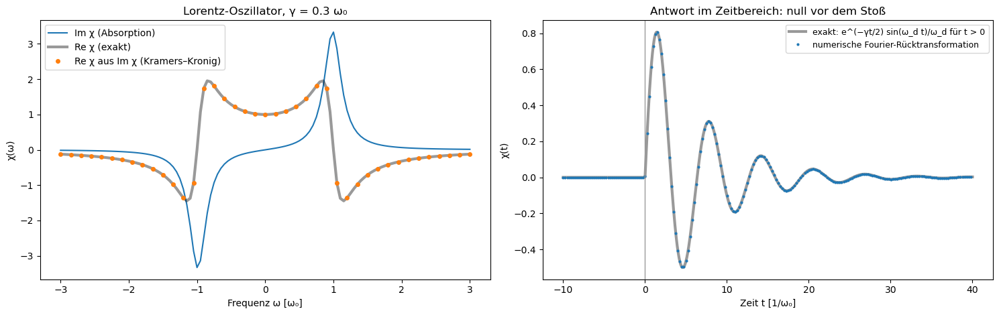

größter Betrag von χ(t) für t < 0 (numerisch): 1.5e-06


In [12]:
complexanalysis.kramers_kronig()

**12. Die Resolvente: Projektoren, Zeitentwicklung und Zustandsdichte**

Die Resolvente G(z) = (z − H)⁻¹ eines Hamilton-Operators hat Pole bei den Eigenwerten. Kurvenintegrale um sie liefern Projektoren und die Zeitentwicklung, ihr Imaginärteil knapp über der reellen Achse die Zustandsdichte.

Die Zustandsdichte hat sechs Spitzen bei den sechs Eigenwerten, schmal und hoch bei kleinem Abstand η zur Achse, breit bei großem. Der Riesz-Projektor, das Integral um einen Eigenwert, weicht um 4.5·10⁻¹⁶ vom Projektor auf den Eigenvektor ab, und e^(−iHt) als Kurvenintegral um 10⁻¹³ von der Matrixexponentialfunktion. Zwischen je zwei Polen der Spur liegt eine Nullstelle.

Riesz-Projektor um E_2 = -1.005: Abweichung von |v><v| 3.9e-16, P² = P: True
e^(−iHt) für t = 1.7 als Kurvenintegral: Abweichung von expm 7.1e-14


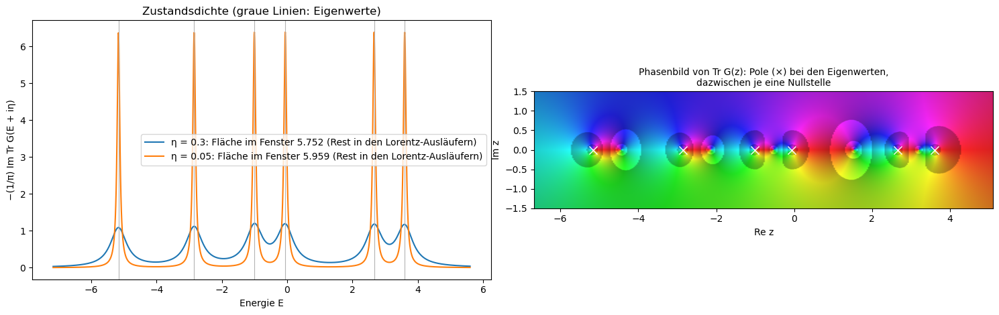

In [13]:
complexanalysis.resolvent()

**13. Zerfall: ein Pol auf dem zweiten Blatt**

Ein Zustand, der an ein Kontinuum gekoppelt ist, zerfällt. Seine Zerfallsrate steckt in einem Pol der fortgesetzten Resolvente, der auf dem zweiten Riemann-Blatt liegt.

Die Überlebenswahrscheinlichkeit fällt über sechs Größenordnungen exponentiell, genau mit der Rate des Pols, Γ = 1.308; Fermis goldene Regel (1.256) ist sichtbar zu langsam. Auf dem ersten Blatt gibt es diesen Pol nicht. Bei t ≈ 502 = 2π/δ taucht der längst zerfallene Zustand wieder auf, weil das Kontinuum hier aus gleichabständigen Niveaus besteht, die wieder in Phase kommen.

goldene Regel Γ = 1.2559; Pol auf dem zweiten Blatt z* = -0.00000-0.65403j, also Γ_Pol = 1.3081 (Näherung Γ/(1 − Γ/(πW)) = 1.3081)
Probe: auf dem ersten Blatt hat 1/(z − Σ(z)) in der unteren Halbebene dort keinen Pol: |z* − Σ_I(z*)| = 1.256
Fit der Überlebenswahrscheinlichkeit für 1 < t < 6: Γ = 1.3061; Rückkehrzeit 2π/δ = 502


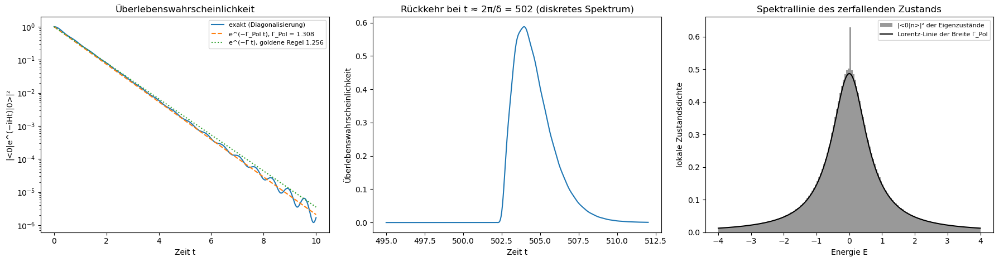

In [14]:
complexanalysis.decay_pole()

**14. Analytische Fortsetzung: Gamma, Zeta und −1/12**

Eine holomorphe Funktion ist durch ihre Werte auf einem kleinen Stück festgelegt. Damit lassen sich die Gamma- und die Zeta-Funktion weit über ihren ursprünglichen Bereich hinaus fortsetzen.

Γ hat Pole bei 0, −1, −2, … mit den Residuen (−1)ⁿ/n! und keine Nullstellen. ζ(−1) = −1/12 folgt aus der Funktionalgleichung; dieselbe Zahl bleibt übrig, wenn man 1 + 2 + 3 + … mit e^(−εn) dämpft und den divergenten Teil 1/ε² abzieht. Auf der kritischen Geraden liegen die ersten Nullstellen bei 14.13, 21.02, 25.01, 30.42 und 32.94.

Res Γ bei s = −0: +1.000000 (Formel (−1)^n/n! = +1.000000)
Res Γ bei s = −1: -1.000000 (Formel (−1)^n/n! = -1.000000)
Res Γ bei s = −2: +0.500000 (Formel (−1)^n/n! = +0.500000)
Res Γ bei s = −3: -0.166667 (Formel (−1)^n/n! = -0.166667)
Γ(1/2)² = 3.1415926536 = π; Spiegelung Γ(s)Γ(1−s) sin(πs)/π bei s = 0.3+0.4i: 1.0000000000+0.0000000000j
ζ(−1) aus der Funktionalgleichung: -0.0833333333; mpmath: -0.0833333333; ζ(0) = -0.5000
ε = 0.1: Σ n e^(−εn) − 1/ε² = -0.08329168  (−1/12 = -0.08333333)
ε = 0.01: Σ n e^(−εn) − 1/ε² = -0.08333292  (−1/12 = -0.08333333)
ε = 0.001: Σ n e^(−εn) − 1/ε² = -0.08333333  (−1/12 = -0.08333333)


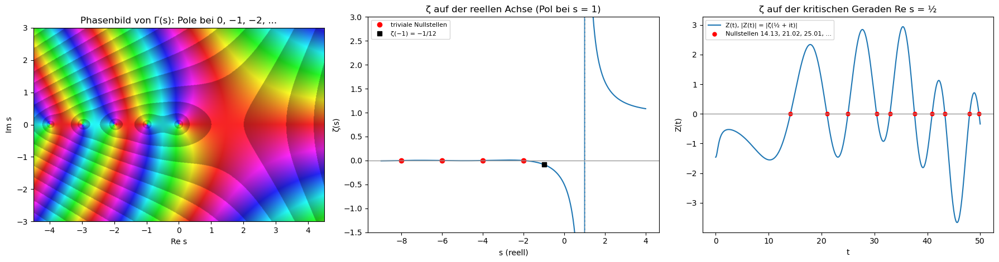

erste Nullstellen auf der kritischen Geraden: [14.1347 21.022  25.0109 30.4249 32.9351]


In [15]:
complexanalysis.continuation()

**15. Lee-Yang: Nullstellen der Zustandssumme**

Ein Phasenübergang ist eine Singularität der freien Energie. Für ein endliches System ist die Zustandssumme ein Polynom ohne Singularität; Lee und Yang zeigten 1952, dass seine Nullstellen im komplexen Magnetfeld auf dem Einheitskreis liegen. Gerechnet wird ein Ferromagnet, in dem jeder Spin mit jedem gekoppelt ist (Übergang bei βJ = 1).

Alle Nullstellen liegen auf |z| = 1. Im ungeordneten Bereich (βJ = 0.6) bleibt eine Lücke um z = 1, ihr Winkel fällt nur langsam (0.79, 0.64, 0.55 für N = 20, 40, 80). Im geordneten Bereich (βJ = 1.6) halbiert er sich mit jeder Verdopplung von N (0.19, 0.09, 0.045): Die Nullstellen erreichen das reelle Feld, und dort entsteht der Phasenübergang. Beim Antiferromagneten gilt der Satz nicht; seine Nullstellen liegen auf der negativen reellen Achse.

Antiferromagnet: |z| reicht von 0.0155 bis 64.5


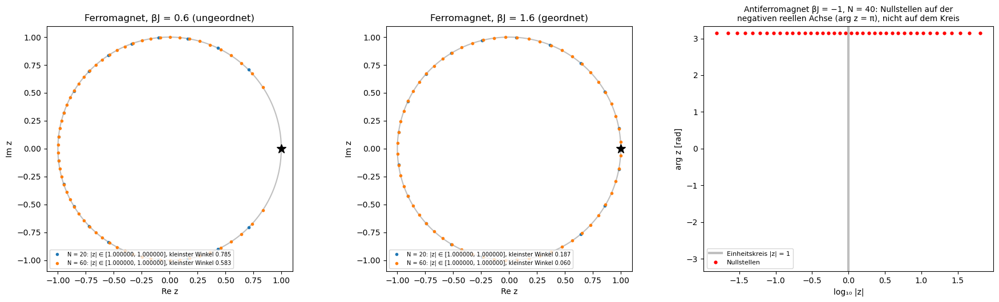

βJ = 0.6: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: [0.7852 0.6414 0.5497]


βJ = 1.0: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: [0.3755 0.2261 0.1356]


βJ = 1.6: kleinster Winkel der Nullstellen zur reellen Achse für N = 20, 40, 80: [0.1866 0.0903 0.0445]


In [16]:
complexanalysis.lee_yang_zeros()

**16. Fourier-Analyse: Werkzeuge**

Die harmonische Analysis zerlegt Funktionen in Grundschwingungen: einen Ton in seine Frequenzen, ein Bild in Streifenmuster, eine Temperaturverteilung in Wellen. In dieser Darstellung werden viele Operationen einfach: Ableiten wird Multiplizieren, Glätten (Falten) auch, Verschieben wird eine Phase. Fourier behauptete 1807 bei der Wärmeleitung, jede Funktion sei eine Reihe aus Sinus und Kosinus; die Frage, in welchem Sinn das stimmt, trieb Riemann, Lebesgue und Cantor an und wurde erst 1966 von Carleson beantwortet. Bereitgestellt werden Fourier-Koeffizienten, Partialsummen, die Fourier-Transformation per FFT und die Breite einer Verteilung.

Die Ausgabe meldet die Werkzeuge bereit.

In [17]:
fourier.load()

Werkzeuge bereit: Fourier-Koeffizienten, Partialsummen, Fourier-Transformation per FFT, Breite einer Verteilung


**17. Glattheit und der Abfall der Fourier-Koeffizienten**

Vier periodische Funktionen, jede eine Stufe glatter: ein Rechteck mit Sprung, ein Dreieck mit Knick, eine Funktion mit Sprung erst in der zweiten Ableitung und der analytische Poisson-Kern.

Mit nur fünf Frequenzen sind die glatten Funktionen fast exakt, das Rechteck wellt sich und schafft den Sprung nicht. Die Koeffizienten fallen wie k⁻¹, k⁻² und k⁻³ (gemessene Steigungen −1.000, −2.000, −3.000), beim Poisson-Kern exponentiell wie 0.5^k. Jede Ableitung mehr bringt eine Potenz von k schneller Abfall: Am Abfall der Koeffizienten liest man die Glattheit ab.

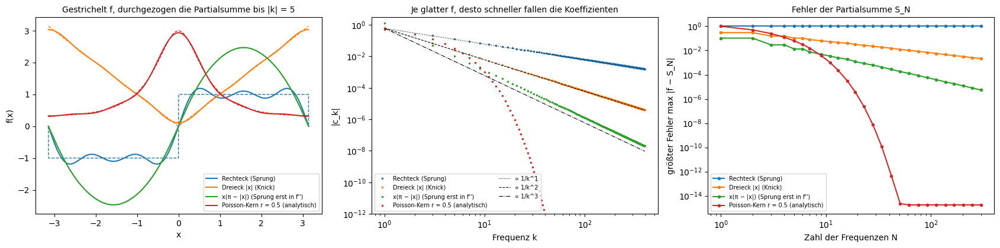

Rechteck (Sprung)                 : Steigung von log|c_k| gegen log k: -1.000;  |c_11| = 0.05787 (Formel 0.05787)
Dreieck |x| (Knick)               : Steigung von log|c_k| gegen log k: -2.000;  |c_11| = 0.00526 (Formel 0.00526)
x(π − |x|) (Sprung erst in f'')   : Steigung von log|c_k| gegen log k: -3.000;  |c_11| = 0.00096 (Formel 0.00096)
Poisson-Kern r = 0.5 (analytisch) : c_11/c_10 = 0.5000 (Theorie r = 0.5), |c_20| = 9.54e-07 (Theorie 9.54e-07)


In [18]:
fourier.smoothness_decay()

**18. Das Gibbs-Phänomen und die Fejér-Mittel**

Die Partialsummen der Fourier-Reihe eines Rechtecks mit wachsender Zahl von Frequenzen, verglichen mit den Fejér-Mitteln, die über die Partialsummen mitteln.

Das Überschwingen am Sprung rückt immer näher an den Sprung, bleibt aber auf der Höhe 1.179, also 8.95 % der Sprunghöhe, für N = 71 genauso wie für N = 1000. Mehr Frequenzen helfen nicht. Das Fejér-Mittel steigt ohne Überschwingen an (höchstens 0.966), dafür flacher, weil sein Kern überall positiv ist, während der Dirichlet-Kern der Partialsummen negative Nebenschwinger hat.

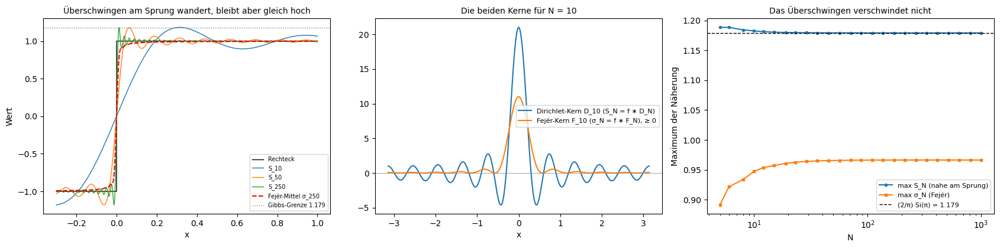

Maximum von S_N bei N = 5, 71, 1000: 1.1884, 1.1790, 1.1790  (Grenzwert (2/π)Si(π) = 1.17898)
Überschwingen in Prozent des Sprungs 2: 8.95%  (Theorie 8.95%);  Fejér-Maximum höchstens 0.9664
Lebesgue-Konstanten (1/2π)∫|D_N| bei N = 5, 71, 1000: 1.961, 3.001, 4.070  (Näherung (4/π²) ln N + 1.27: 1.922, 2.998, 4.070)


In [19]:
fourier.gibbs_phenomenon()

**19. Parseval und das Basel-Problem**

Die Energie einer Funktion ist die Summe der Quadrate ihrer Fourier-Koeffizienten (Parseval). Angewendet auf den Sägezahn ergibt das eine Summe, die Euler 1734 berechnete.

Für den Sägezahn ist (1/2π)∫x² = π²/3, und daraus folgt Σ1/k² = π²/6; ebenso Σ1/k⁴ = π⁴/90, auf acht Stellen. Der Fehler einer Partialsumme ist genau die Energie der weggelassenen Koeffizienten. Beim Rechteck trägt der Grundton allein 81 % der Energie (8/π²), bis k = 5 schon 93 %.

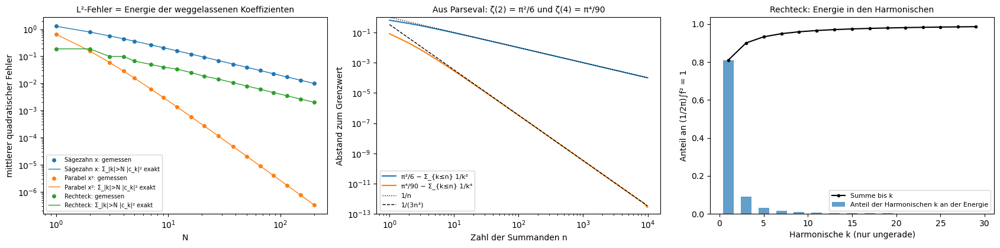

Sägezahn: (1/2π)∫x² = 3.289868 = π²/3 = 3.289868;  Σ|c_k|² über |k| ≤ 400 = 3.284855, fehlender Rest Σ_|k|>400 1/k² = 0.004994
Daraus ζ(2) = π²/6 = 1.644934;  Σ 1/k² bis 10 000 = 1.644834
Daraus ζ(4) = π⁴/90 = 1.08232323;  Σ 1/k⁴ bis 10 000 = 1.08232323
Rechteck: Grundton trägt 0.8106 der Energie (Theorie 8/π² = 0.8106), bis k = 5: 0.9331
Rechteck, N = 10: L²-Fehler der Partialsumme 0.0404 (exakt 0.0404), des Fejér-Mittels 0.0739 (die Partialsumme ist die beste L²-Näherung)


In [20]:
fourier.parseval()

**20. Fourier-Transformation: Paare und Eigenfunktionen**

Drei Funktionen auf der ganzen Geraden und ihre Transformierten, numerisch mit der FFT und exakt, dazu die Hermite-Funktionen.

Die Gauß-Funktion bleibt eine Gauß-Funktion, das Rechteck wird zur sinc-Funktion mit negativen Nebenschwingern, der Laplace-Puls zur Lorentz-Kurve. Die FFT trifft die Gauß-Funktion auf 5·10⁻¹⁵, das Rechteck wegen seiner Kanten nur auf 10⁻³; die Energie ist auf beiden Seiten gleich (Plancherel). Die Hermite-Funktionen, die Eigenzustände des harmonischen Oszillators, sind Eigenfunktionen der Transformation mit den Eigenwerten 1, −i, −1, i.

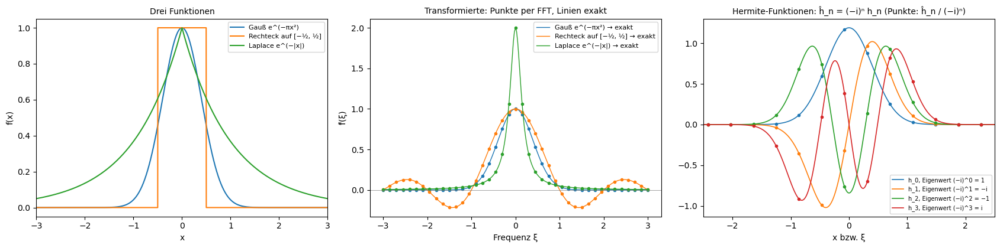

Gauß e^(−πx²)         : größter Fehler der FFT-Näherung für |ξ| ≤ 3: 4.9e-15;  Plancherel ∫|f|² = 0.707107, ∫|f̂|² = 0.707107
Rechteck auf [−½, ½]  : größter Fehler der FFT-Näherung für |ξ| ≤ 3: 1.5e-03;  Plancherel ∫|f|² = 0.998535, ∫|f̂|² = 0.998535
Laplace e^(−|x|)      : größter Fehler der FFT-Näherung für |ξ| ≤ 3: 1.0e-06;  Plancherel ∫|f|² = 1.000002, ∫|f̂|² = 1.000002
Eigenwerte ⟨h_n, ĥ_n⟩ für n = 0 … 7: +1.000-0.000i, +0.000-1.000i, -0.999-0.000i, +0.000+0.999i, +0.999+0.000i, -0.000-0.998i, -0.998-0.000i, -0.000+0.998i


In [21]:
fourier.transform_pairs()

**21. Unschärfeprinzipien**

Eine Funktion kann nicht zugleich im Ort und in der Frequenz schmal sein: Das Produkt der Breiten ist mindestens 1/(4π). Dasselbe gilt in diskreter Form für die Zahl der Einträge ungleich null (Donoho-Stark).

Nur die Gauß-Funktion erreicht die Grenze; das Dreieck liegt 1.10-fach, der Laplace-Puls 1.41-fach darüber, eine Gauß-Funktion mit Chirp √5-fach, weil sie viele Frequenzen nacheinander durchläuft. 300 zufällige Wellenpakete liegen alle über der Grenze. Im Diskreten erreichen Kämme die Schranke |supp f|·|supp f̂| ≥ N genau; zufällige dünne Vektoren haben eine volle Transformierte.

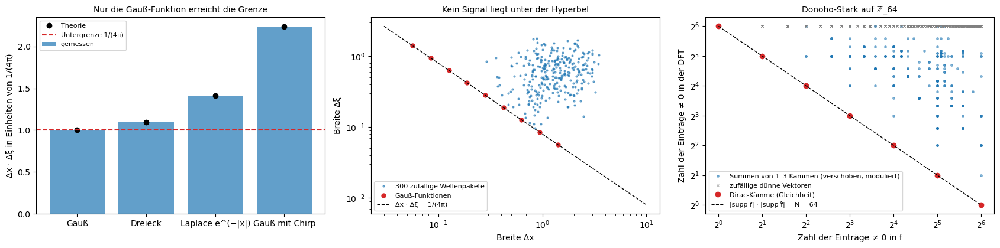

Gauß             : Δx·Δξ = 0.0796 = 1.000 × 1/(4π)  (Theorie 1.000)
Dreieck          : Δx·Δξ = 0.0872 = 1.096 × 1/(4π)  (Theorie 1.095)
Laplace e^(−|x|) : Δx·Δξ = 0.1126 = 1.415 × 1/(4π)  (Theorie 1.414)
Gauß mit Chirp   : Δx·Δξ = 0.1779 = 2.236 × 1/(4π)  (Theorie 2.236)
Zufällige Wellenpakete: kleinstes Produkt 1.019 × 1/(4π)
Donoho-Stark: kleinstes |supp f|·|supp f̂| bei den Kammsummen 64, bei den reinen Kämmen [64]; zufällige dünne Vektoren mit voller DFT (64 Einträge ≠ 0): 100%


In [22]:
fourier.uncertainty()

**22. Der Faltungssatz**

Faltung im Ort ist Multiplikation in der Frequenz. Ein verrauschtes Signal wird mit einem Gauß-Kern geglättet, direkt und über die FFT.

Die Faltung entfernt das Rauschen; der Sprung wird auf die Breite des Kerns verschmiert. Im Spektrum sieht man warum: Der Kern multipliziert die hohen Frequenzen mit fast null, und dort sitzt der Rauschboden. Direkt und über die FFT ergibt sich dasselbe (10⁻¹⁵), wenn man vorher mit Nullen auffüllt; die FFT ist bei 32 768 Punkten rund 300-mal schneller.

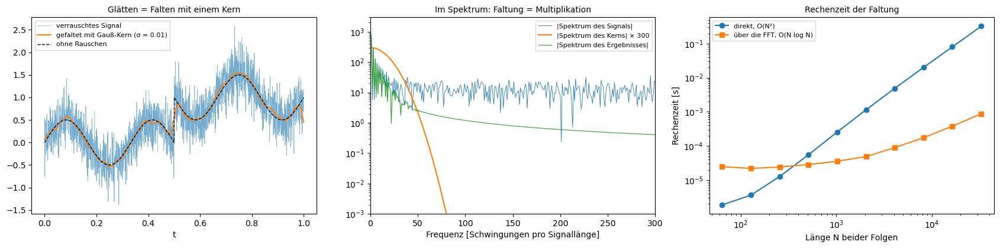

Direkte Faltung gegen FFT-Faltung: größter Unterschied 1.6e-15
FFT mit Auffüllen gegen direkt: 1.3e-15;  ohne Auffüllen (zyklisch): 0.43 (Fehler an den Rändern)
Rechenzeit bei N = 32768: direkt 323.7 ms, FFT 0.88 ms, Verhältnis 369


In [23]:
fourier.convolution()

**23. Die Poissonsche Summenformel**

Die Summe einer Funktion über alle ganzen Zahlen ist die Summe ihrer Fourier-Transformierten über alle ganzen Zahlen. Eine langsam konvergierende Summe wird so zu einer schnellen.

Für die Theta-Funktion braucht die eine Seite bei kleinem t 33 Terme, die andere einen einzigen; bei großem t ist es umgekehrt, beide Seiten stimmen auf 15 Stellen überein. Σ1/(n² + 1) hat nach 2000 Termen noch einen Fehler von 10⁻³; die Poisson-Seite erreicht π·coth π mit sieben Termen auf Rechengenauigkeit.

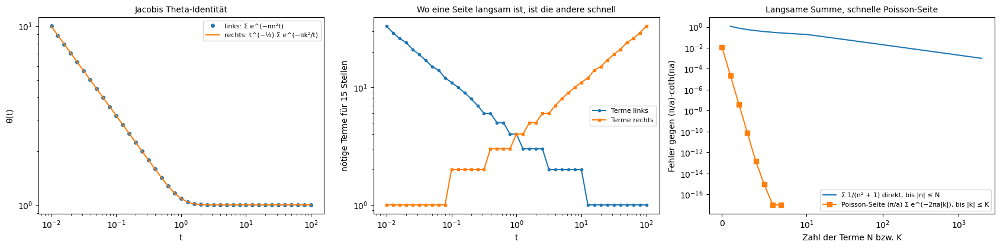

t =   0.01: links 10.000000000000002 (33 Terme), rechts 10.000000000000000 (1 Terme)
t =   1.00: links 1.086434811213308 (4 Terme), rechts 1.086434811213308 (4 Terme)
t = 100.00: links 1.000000000000000 (1 Terme), rechts 1.000000000000000 (33 Terme)
Σ_n 1/(n² + 1): exakt π·coth(π) = 3.153348094937; direkt mit |n| ≤ 2000: Fehler 1.0e-03; Poisson-Seite mit |k| ≤ 7: Fehler 0.0e+00


In [24]:
fourier.poisson_summation()

**24. Diskrete Fourier-Transformation und FFT**

Die DFT als Matrix: Was ist ihre Struktur, und wie macht die FFT (Gauß 1805, Cooley und Tukey 1965) aus N² Operationen N log N?

Die Matrix ist bis auf einen Faktor unitär, ihre vierte Potenz ist die Einheit, und ihre Eigenwerte liegen nur auf 1, −1, i und −i. Eine eigene FFT in Python stimmt mit numpy auf 5·10⁻¹⁴ überein. Bei N = 2¹⁴ sind das 2.3·10⁵ statt 2.7·10⁸ Operationen; numpy braucht dafür etwa 0.1 ms.

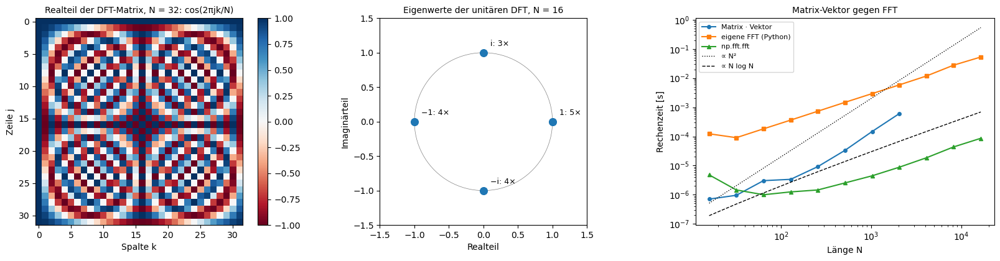

Unitär: ‖F F* − I‖ = 9.1e-15;  F⁴ = I: True;  F² kehrt die Indizes um (j → −j mod N): True
Vielfachheiten der Eigenwerte für N = 16: {'1': 5, '−1': 4, '−i': 4, 'i': 3}
Eigene FFT gegen np.fft.fft (N = 1024): größter Unterschied 4.6e-14
Operationen bei N = 2^14: N² = 2.68e+08, N·log₂N = 2.29e+05; Zeit eigene FFT 52.7 ms, np.fft 0.086 ms


In [25]:
fourier.dft_fft()

**25. Abtasttheorem und Aliasing**

Ein Signal ohne Frequenzen über B lässt sich aus Abtastwerten im Abstand 1/(2B) exakt zurückgewinnen (Shannon). Was passiert darunter?

Mit 10 Hz abgetastet sind ein 7-Hz-Sinus und ein 3-Hz-Sinus nicht zu unterscheiden: Frequenzen über 5 Hz werden gespiegelt, 12 Hz erscheint als 2 Hz. Ein Signal bis 4.6 Hz wird aus 10 Hz und 20 Hz auf 3·10⁻⁴ bzw. 6·10⁻⁶ genau rekonstruiert, aus 6 Hz völlig falsch (Fehler 1.6).

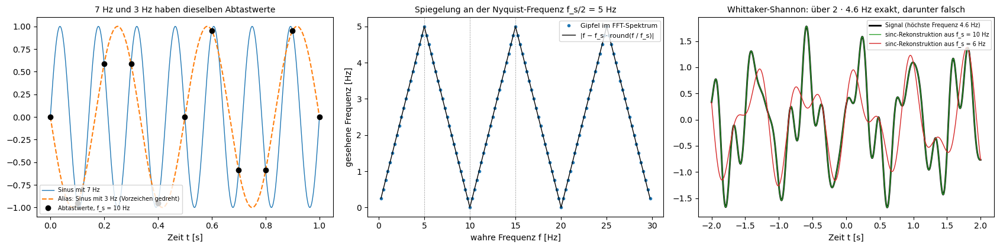

Gesehene Frequenzen bei f_s = 10 Hz: 7 Hz → 3.00 Hz, 12 Hz → 2.00 Hz, 18.5 Hz → 1.50 Hz
f_s =   20 Hz (über 2 · 4.6 = 9.2 Hz): größter Rekonstruktionsfehler auf [−2, 2] = 6.0e-06
f_s =   10 Hz (über 2 · 4.6 = 9.2 Hz): größter Rekonstruktionsfehler auf [−2, 2] = 2.5e-04
f_s =    6 Hz (unter 2 · 4.6 = 9.2 Hz): größter Rekonstruktionsfehler auf [−2, 2] = 1.6e+00


In [26]:
fourier.sampling()

**26. Leckeffekt und Fensterfunktionen**

Ein starker Ton bei 50.3 Hz und ein Ton bei 61 Hz mit tausendfach kleinerer Amplitude (−60 dB). Ein endlicher Ausschnitt verschmiert jeden Ton über das Spektrum; Fensterfunktionen dämpfen das.

Mit dem Rechteckfenster liegt das Leck des starken Tons bei 61 Hz bei −33 dB, und der schwache Ton verschwindet darin. Mit dem Hann-Fenster sinkt das Leck auf −74 dB, und der Ton steht bei −59 dB heraus; mit Blackman-Harris liegt er sauber bei −60.0 dB über einem Leck von −102 dB. Der Preis ist eine breitere Hauptkeule: Man tauscht Frequenzauflösung gegen Dynamikumfang.

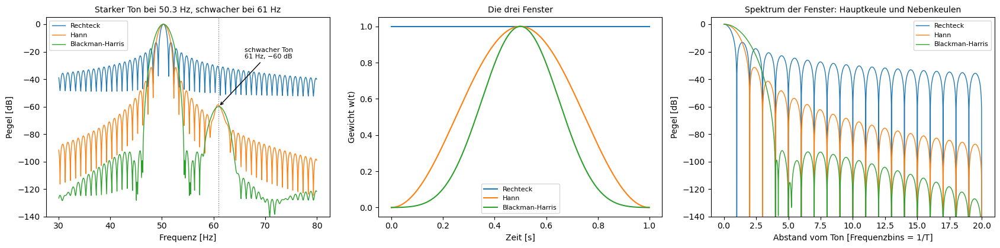

Rechteck       : höchste Nebenkeule  -13.3 dB, Hauptkeule 2.0 Bins breit, Verlust bei halbem Bin -3.92 dB; bei 61 Hz:  -32.6 dB mit,  -32.3 dB ohne schwachen Ton
Hann           : höchste Nebenkeule  -31.5 dB, Hauptkeule 4.0 Bins breit, Verlust bei halbem Bin -1.42 dB; bei 61 Hz:  -58.9 dB mit,  -73.5 dB ohne schwachen Ton
Blackman-Harris: höchste Nebenkeule  -92.0 dB, Hauptkeule 8.0 Bins breit, Verlust bei halbem Bin -0.83 dB; bei 61 Hz:  -60.0 dB mit, -101.6 dB ohne schwachen Ton


In [27]:
fourier.leakage()

**27. Zeit-Frequenz-Analyse: das Spektrogramm**

Ein Signal mit einem Klick, einem Chirp und zwei nahen Tönen bei 200 und 215 Hz, mit einem kurzen (32 ms) und einem langen Fenster (512 ms).

Das kurze Fenster zeigt den Klick als scharfe Linie (8 ms), lässt aber die beiden Töne zu einem pulsierenden Band verschmelzen. Das lange Fenster trennt die Töne mit einem Einbruch von 42 dB, verschmiert aber den Klick auf 128 ms. Zeit- und Frequenzauflösung lassen sich nicht zugleich verbessern: Das ist die Unschärfe aus Schritt 21 in der Praxis.

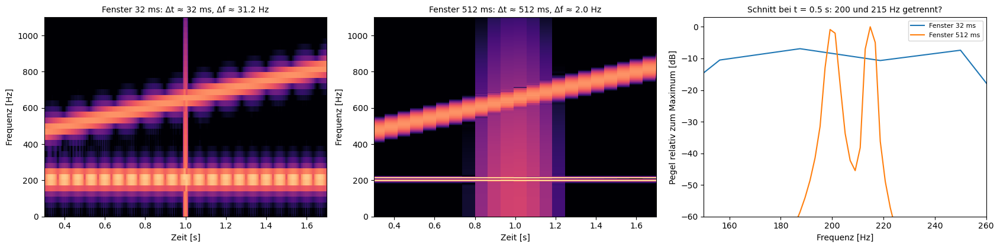

Fenster  128 Punkte ( 32 ms): Frequenzauflösung f_s/N =  31.2 Hz; Klick oberhalb halber Höhe   8.0 ms lang; Einbruch zwischen 200 und 215 Hz:    0.0 dB
Fenster 2048 Punkte (512 ms): Frequenzauflösung f_s/N =   2.0 Hz; Klick oberhalb halber Höhe 128.0 ms lang; Einbruch zwischen 200 und 215 Hz:  -42.3 dB


In [28]:
fourier.spectrogram()

**28. Wavelets gegen Fourier: wer braucht weniger Koeffizienten?**

Ein Signal aus Blöcken und ein glattes Signal, komprimiert auf 6 % der Koeffizienten, einmal mit der Kosinus-Transformation (DCT) und einmal mit Haar-Wavelets.

Das Blocksignal hat nur 55 Haar-Koeffizienten ungleich null und wird damit exakt wiedergegeben, die DCT schwingt an jedem Sprung (Fehler 9 %). Beim glatten Signal ist es umgekehrt: DCT-Fehler 10⁻⁵, Haar 3 %. Welche Basis am besten komprimiert, hängt davon ab, wie das Signal aussieht; JPEG nutzt die DCT, JPEG 2000 Wavelets.

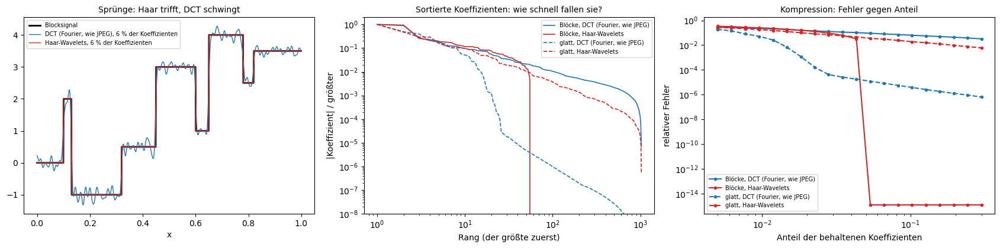

Haar ist orthonormal: Rücktransformation exakt bis 6.2e-15, Energie erhalten True
Blöcke: relativer Fehler mit 6 % (3 %) der Koeffizienten: DCT 8.62e-02 (1.22e-01), Haar 1.28e-15 (8.45e-02); Haar-Koeffizienten ≠ 0: 55 von 1024
glatt : relativer Fehler mit 6 % (3 %) der Koeffizienten: DCT 1.01e-05 (3.67e-05), Haar 3.29e-02 (6.59e-02); Haar-Koeffizienten ≠ 0: 1024 von 1024


In [29]:
fourier.wavelets()

**29. Die Wärmeleitungsgleichung: Fouriers ursprüngliches Problem**

Ein heißes Stück in einem Ring. In der Fourier-Basis zerfällt jede Mode für sich, die Mode k mit der Rate k².

Die Kanten runden sich sofort ab, danach bleibt eine Kosinuswelle um den erhaltenen Mittelwert 0.316. Die Moden 1, 2, 3 und 5 zerfallen mit den Raten 1, 4, 9 und 25; die Lösung ist zugleich die Faltung mit einem Gauß-Kern (Unterschied 10⁻¹⁵). Ein explizites Differenzenverfahren ist stabil für einen Zeitschritt unter dx²/(2D) und explodiert knapp darüber auf 10²⁹.

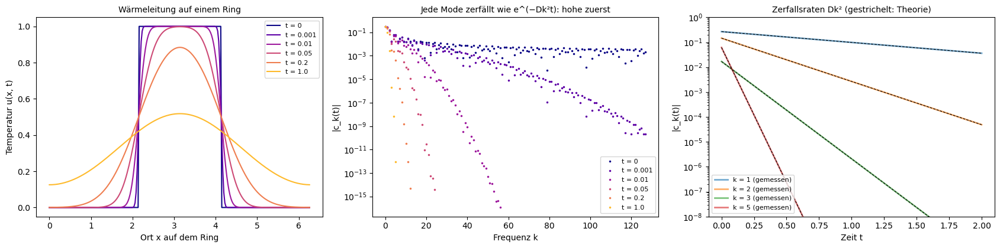

t = 0.01: Fourier-Lösung gegen Faltung mit dem periodisierten Gauß-Kern: größter Unterschied 1.3e-15
t = 0.2: Fourier-Lösung gegen Faltung mit dem periodisierten Gauß-Kern: größter Unterschied 3.3e-16
Mittelwert bleibt erhalten: 0.316406 → 0.316406;  Abweichung vom Mittelwert bei t = 2 und 3: 0.07232, 0.02657 (Verhältnis 0.3674, Theorie e^−1 = 0.3679)
Explizites Differenzenverfahren mit dt = 0.45 · dx²/D, 400 Schritte: max |u| = 0.967 (stabil)
Explizites Differenzenverfahren mit dt = 0.55 · dx²/D, 400 Schritte: max |u| = 4.9e+29 (instabil)


In [30]:
fourier.heat_equation()

**30. Beugung: Fourier-Optik in zwei Dimensionen**

Im Fernfeld ist das Beugungsbild die zweidimensionale Fourier-Transformation der Öffnung. Eine Kreisöffnung und ein Doppelspalt.

Die Kreisöffnung erzeugt das Airy-Muster; der erste dunkle Ring liegt bei 0.605 (Theorie 1.22/D = 0.610), und im zentralen Scheibchen stecken 83.8 % der Energie. Das begrenzt die Auflösung jedes Teleskops. Der Doppelspalt erzeugt Streifen im Abstand 1/d unter der Hülle eines einzelnen Spalts.

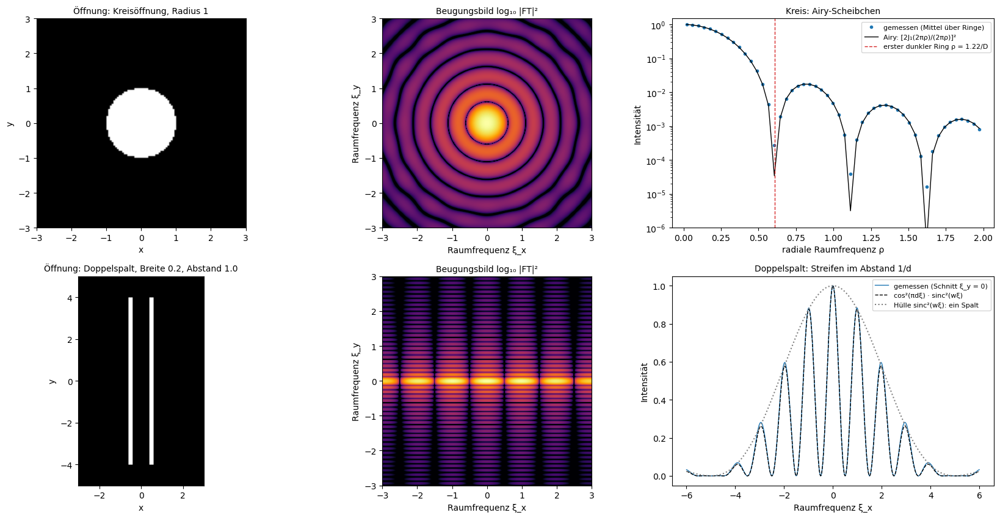

Erster dunkler Ring: gemessen bei ρ = 0.605 (Raster 0.039), Theorie 3.8317/(2πa) = 0.6098 = 1.22/D
Anteil der Energie im zentralen Scheibchen: 0.838 (Theorie 0.838)
Doppelspalt: Minima bei ξ = [-2.5   -1.504 -0.508  0.508  1.504  2.5  ] (Theorie ±0.5, ±1.5, ±2.5: Abstand 1/d = 1.0)


In [31]:
fourier.diffraction()

**31. Harmonische Analysis auf endlichen Gruppen**

Die Fourier-Transformation gibt es auf jeder endlichen abelschen Gruppe. Auf dem Hyperwürfel zerlegt sie Boolesche Funktionen in Paritäten; auf ℤ_N findet sie in Shors Algorithmus die Periode.

Der Diktator hat sein ganzes Gewicht auf Stufe 1, die Parität auf Stufe 9, die Mehrheit 0.673 auf Stufe 1 (für großes n gegen 2/π). Die Summe der Gewichte ist immer 1 (Parseval). Für 2^x mod 21 konzentriert die Transformation die Wahrscheinlichkeit auf sechs Gipfel; aus der Periode 6 folgt ggT(2³ ± 1, 21) und damit 21 = 3 · 7.

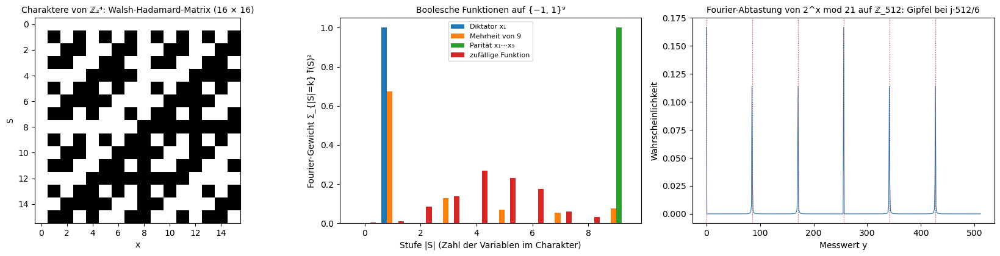

Diktator x₁       : Σ f̂(S)² = 1.000;  Gewicht auf Stufe 1: 1.000;  Gesamteinfluss Σ|S| f̂(S)² = 1.000
Mehrheit von 9    : Σ f̂(S)² = 1.000;  Gewicht auf Stufe 1: 0.673;  Gesamteinfluss Σ|S| f̂(S)² = 2.461
Parität x₁⋯x₉     : Σ f̂(S)² = 1.000;  Gewicht auf Stufe 1: 0.000;  Gesamteinfluss Σ|S| f̂(S)² = 9.000
zufällige Funktion: Σ f̂(S)² = 1.000;  Gewicht auf Stufe 1: 0.009;  Gesamteinfluss Σ|S| f̂(S)² = 4.539
Mehrheit: Stufe-1-Gewicht exakt 9·(C(8,4)/2⁸)² = 0.673, für n → ∞ gegen 2/π = 0.637
Periode von 2^x mod 21: 6; Wahrscheinlichkeit, einen der beiden nächsten Werte zu j·512/6 zu messen: 0.903
Aus r = 6: 2^3 mod 21 = 8;  ggT(8 − 1, 21) = 7,  ggT(8 + 1, 21) = 3  →  21 = 3 · 7
Messwert y = 85: y/512 ≈ 1/6 → Nenner 6  (= Periode)
Messwert y = 171: y/512 ≈ 1/3 → Nenner 3  (Teiler von r; ein zweiter Messwert gibt r = 6)
Messwert y = 427: y/512 ≈ 5/6 → Nenner 6  (= Periode)


In [32]:
fourier.finite_groups()

**32. Funktionalanalysis: Werkzeuge**

Die Funktionalanalysis behandelt Funktionen als Punkte eines Vektorraums, mit Länge (Norm) und Winkel (Skalarprodukt), und die Operatortheorie die linearen Abbildungen zwischen solchen Räumen: die Ableitung, ein Integral, den Hamilton-Operator. Vieles aus der linearen Algebra überträgt sich, aber nicht alles: Die Einheitskugel ist nicht kompakt, ein Operator kann ein Spektrum ohne Eigenwerte haben, und die Ableitung ist nur auf einem Teil des Raums definiert. Die Theorie entstand um 1900 aus Integralgleichungen (Fredholm, Hilbert, Riesz), Banach fasste sie 1932 zusammen, und von Neumann gab damit der Quantenmechanik ihre Grundlage. Bereitgestellt werden ein Gitter, die L²-Norm, die Nyström-Matrix eines Integraloperators und die Operatornorm.

Die Ausgabe meldet die Werkzeuge bereit.

In [33]:
functional.load()

Werkzeuge bereit: Gitter, L²-Norm, Nyström-Matrix, Operatornorm


**33. Unendlich viele Dimensionen: Kompaktheit und Normen**

In unendlich vielen Dimensionen ist die Einheitskugel nicht kompakt, und verschiedene Normen messen verschiedene Konvergenz. Untersucht werden die Einheitsvektoren und zwei Folgen in ℓ¹, ℓ² und ℓ^∞.

Alle Einheitsvektoren e_n haben voneinander den Abstand √2: Die Folge hat keine konvergente Teilfolge, die Kugel ist nicht kompakt. Der Vektor (1/N, …, 1/N) geht in ℓ² und ℓ^∞ gegen null, hat in ℓ¹ aber immer die Norm 1. Die Folge (1, 1/2, …, 1/N) wächst in ℓ¹ wie ln N (12.1 bei N = 10⁵), in ℓ² bleibt sie bei π/√6 = 1.2825: Sie liegt in ℓ², aber nicht in ℓ¹.

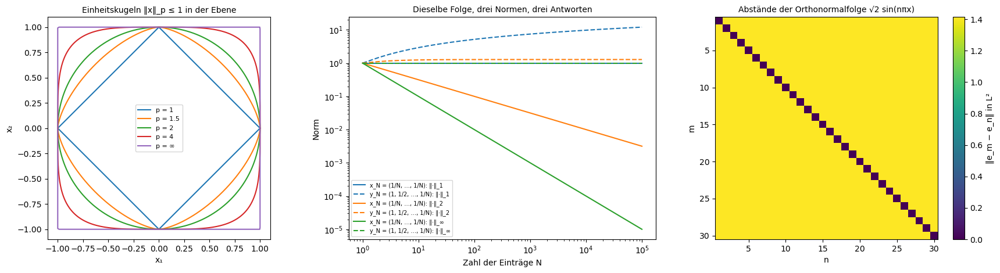

Abstände e_m − e_n (m ≠ n): kleinster 1.414214, größter 1.414214, √2 = 1.414214;  Normen der e_n: 1.000000 bis 1.000000
N =     10: x_N hat ‖·‖₁ = 1.0000, ‖·‖₂ = 0.3162, ‖·‖_∞ = 0.10000;  y_N hat ‖·‖₁ = 2.9290, ‖·‖₂ = 1.2449 (Grenze π/√6 = 1.2825)
N =   1000: x_N hat ‖·‖₁ = 1.0000, ‖·‖₂ = 0.0316, ‖·‖_∞ = 0.00100;  y_N hat ‖·‖₁ = 7.4855, ‖·‖₂ = 1.2822 (Grenze π/√6 = 1.2825)
N = 100000: x_N hat ‖·‖₁ = 1.0000, ‖·‖₂ = 0.0032, ‖·‖_∞ = 0.00001;  y_N hat ‖·‖₁ = 12.0901, ‖·‖₂ = 1.2825 (Grenze π/√6 = 1.2825)


In [34]:
functional.infinite_dimensions()

**34. Schwache Konvergenz und Vollständigkeit**

sin(nx) wird nicht kleiner, aber sein Skalarprodukt mit jeder festen Funktion geht gegen null: schwache Konvergenz. Dazu die Frage, welche Grenzwerte ein Raum enthalten muss.

Die Norm bleibt √π, die Skalarprodukte fallen wie 1/n beim Rechteck mit Sprung, wie 1/n² beim Dreieck und schneller als jede Potenz bei der Gauß-Glocke: Wieder entscheidet die Glattheit. sin²(nx) konvergiert schwach gegen 1/2. Glatte Funktionen, die einem Sprung immer näher kommen, konvergieren in L² (Abstand 0.014 bei n = 1000), aber nie gleichmäßig (der größte Abstand bleibt 0.5): Der Grenzwert ist nicht stetig, liegt aber im vollständigen Raum L².

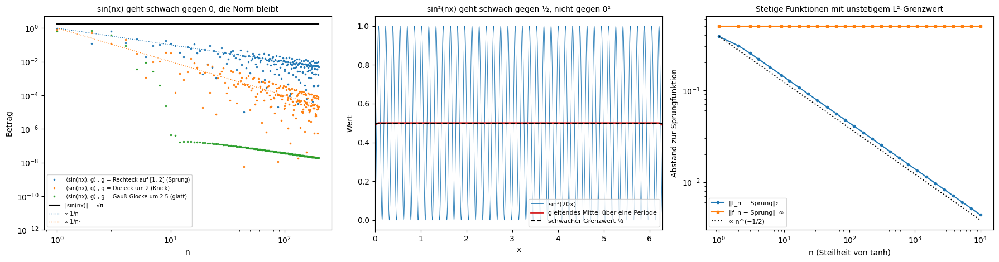

Rechteck auf [1, 2] (Sprung)   |⟨sin(nx), g⟩| bei n = 10, 100, 200: 1.25e-01, 3.76e-03, 5.06e-03
Dreieck um 2 (Knick)           |⟨sin(nx), g⟩| bei n = 10, 100, 200: 3.36e-02, 2.40e-05, 2.18e-05
Gauß-Glocke um 2.5 (glatt)     |⟨sin(nx), g⟩| bei n = 10, 100, 200: 4.36e-07, 3.69e-08, 1.86e-08
‖sin(nx)‖ zwischen 1.772454 und 1.772454 (√π = 1.772454)
⟨sin²(nx), g⟩ für die Gauß-Glocke, n = 1, 5, 20, 100: [0.518841, 0.626655, 0.626657, 0.626657];  ½∫g = 0.626657
L²-Abstand zum Sprung bei n = 10, 100, 1000: ['0.1390', '0.0439', '0.0139'];  Supremumsabstand immer 0.5000
Cauchy in L²: ‖f_n − f_2n‖₂ für n = 10, 100, 1000: ['0.0595', '0.0188', '0.0059']


In [35]:
functional.weak_convergence()

**35. Hahn-Banach: eine Hyperebene trennt Verschränkung ab**

Nach Hahn-Banach lässt sich ein Punkt außerhalb einer konvexen Menge durch eine Hyperebene von ihr trennen. Die separablen Zustände zweier Qubits bilden eine konvexe Menge; die trennende Hyperebene heißt Verschränkungszeuge.

Der Zeuge ist auf 20 000 Produktzuständen und ihren Mischungen nie negativ, auf verschränkten Zuständen kann er negativ werden. Der Werner-Zustand ist ab p = 1/3 verschränkt (gemessen 0.334). Ein einzelner Zeuge sieht aber nur einen kleinen Teil: Von zufälligen Zuständen sind 75 % verschränkt, zwei Zeugen zusammen erkennen davon nur 4.6 %.

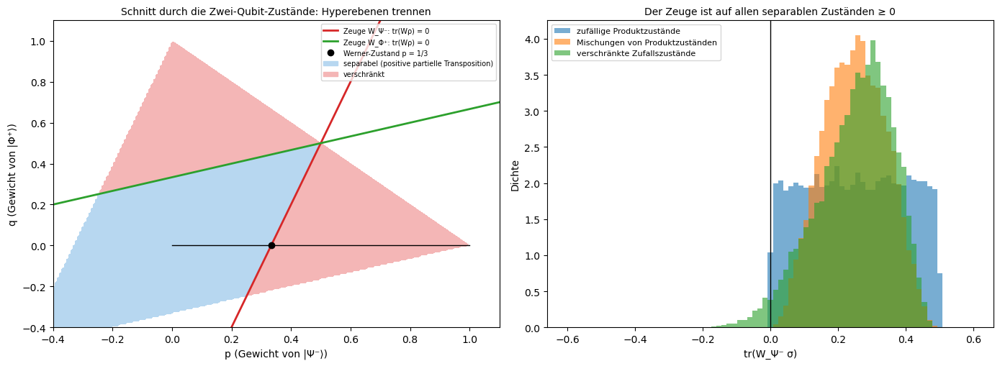

tr(Wσ): kleinster Wert auf 20 000 Produktzuständen 5.90e-06, auf 20 000 Mischungen 0.0120
Werner-Zustand: verschränkt ab p = 0.334 (Theorie 1/3), tr(Wρ_p) = 1/4 − 3p/4 bei p = 0.5: -0.1250
Zufällige Zustände: 0.752 verschränkt; davon erkennt W_Ψ⁻ 0.025, W_Ψ⁻ oder W_Φ⁺ zusammen 0.046


In [36]:
functional.hahn_banach()

**36. Riesz-Darstellung, Sobolev-Raum und Kern-Hilberträume**

In L² ist der Wert einer Funktion an einem Punkt nicht stetig: Eine schmale Spitze hat kleine Norm, aber den Wert 1. Im Sobolev-Raum H¹, der auch die Ableitung misst, ist er stetig und nach Riesz ein Skalarprodukt mit einer Kernfunktion. Darauf beruhen die Kernmethoden des maschinellen Lernens.

Das Verhältnis von Wert zu L²-Norm wächst für schmale Spitzen unbegrenzt (33.6), in H¹ bleibt es unter der Schranke 1.06. Die Kernfunktion reproduziert f(x₀) auf acht Stellen. Nach dem Representer-Theorem liegt die beste Regression in der Hülle der Kernfunktionen an den 20 Datenpunkten (Abweichung 3·10⁻⁹ zur Lösung mit 221 Funktionen). Die Regularisierung λ entscheidet zwischen Überanpassung (λ = 0.0001, Fehler 0.51) und Glättung (λ = 0.01, Fehler 0.16).

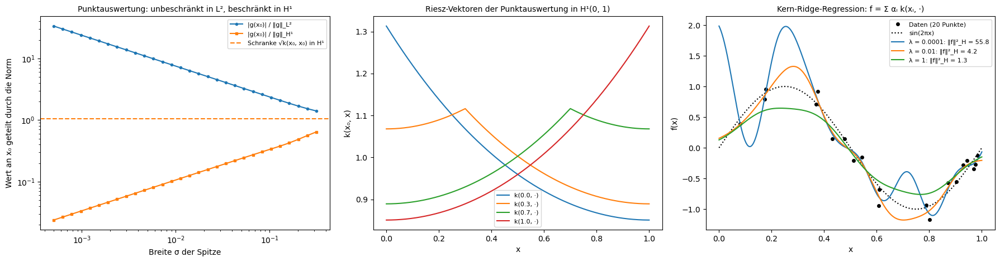

Reproduzierende Eigenschaft in H¹: x₀ = 0.0: ⟨k, f⟩ = 0.00000000, f(x₀) = 0.00000000, x₀ = 0.3: ⟨k, f⟩ = 0.87332691, f(x₀) = 0.87332691, x₀ = 0.7: ⟨k, f⟩ = 1.35320937, f(x₀) = 1.35320937, x₀ = 1.0: ⟨k, f⟩ = 1.14112001, f(x₀) = 1.14112001
Spitze mit σ = 5.0e-04: Verhältnis in L² 33.6, in H¹ 0.0238;  Schranke √k(x₀,x₀) = 1.0566
Representer-Theorem (λ = 0.01): Minimierung über 221 Kernfunktionen weicht von der Lösung mit 20 um höchstens 3.1e-09 ab
Fehler gegen sin(2πx) auf [0, 1]: λ = 0.0001: 0.509, λ = 0.01: 0.158, λ = 1: 0.195


In [37]:
functional.riesz_sobolev()

**37. Beschränkt oder unbeschränkt: Ableitung, Green-Operator, Neumann-Reihe**

Die Ableitung kann eine kleine Funktion groß machen, ihre Umkehrung, der Green-Operator, nicht. Gelöst wird die Integralgleichung u − λKu = f (Fredholm), einmal als Neumann-Reihe und einmal direkt.

Die Norm der diskreten Ableitung wächst wie 2n (1600 bei n = 800), die des Green-Operators geht gegen 1/π²: Die Ableitung ist unbeschränkt. Die Neumann-Reihe konvergiert nur für λ < π², bei λ = 5 auf 10⁻¹⁵, bei 9 langsam, bei 12 gar nicht, obwohl die Gleichung dort eine eindeutige Lösung hat. Unendlich wird die Lösung nur bei den Eigenwerten π², 9π², …; bei 4π² nicht, weil f = 1 dort keinen Anteil hat.

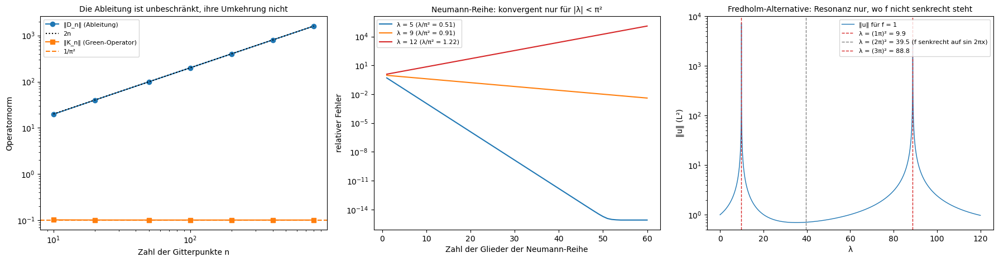

‖D_n‖ für n = [10, 20, 50, 100, 200, 400, 800]: [19.8, 39.9, 100.0, 200.0, 400.0, 800.0, 1600.0];  ‖K_n‖: [0.10216, 0.10153, 0.10135, 0.10133, 0.10132, 0.10132, 0.10132]  (1/π² = 0.10132)
Neumann-Reihe nach 60 Gliedern: λ = 5: 7.9e-16, λ = 9: 3.9e-03, λ = 12: 1.2e+05
Nyström-Lösung gegen exakte Formel bei λ = [20.0, 50.0, 100.0]: Abweichung ['9.9e-06', '5.2e-05', '9.3e-04']
Überlappung ⟨1, √2 sin(kπx)⟩ für k = 1 … 4: [0.900319, 0.0, 0.300112, 0.0]  (Formel 2√2/(kπ) für ungerade k)


In [38]:
functional.bounded_unbounded()

**38. Kompakte Operatoren: Mercer und Karhunen-Loève**

Ein kompakter Operator ist fast eine endliche Matrix: Seine Eigenwerte fallen gegen null. Die Kovarianz eines Zufallsprozesses ist ein solcher Operator, und ihre Eigenfunktionen zerlegen den Prozess in unkorrelierte Teile (Karhunen-Loève): Hauptkomponenten in unendlich vielen Dimensionen.

Für die Brownsche Bewegung sind die Eigenwerte 1/((k − ½)²π²), auf sechs Stellen, und ihre Summe ist 1/2. Die erste Komponente trägt 81 % der Varianz, 20 Komponenten 99 %. Bei Brownscher Bewegung und Ornstein-Uhlenbeck fallen die Eigenwerte wie k⁻², beim glatten Gauß-Kern schneller als exponentiell (λ₃₀/λ₁ = 7·10⁻¹³): Glatte Kerne kommen mit wenigen Komponenten aus.

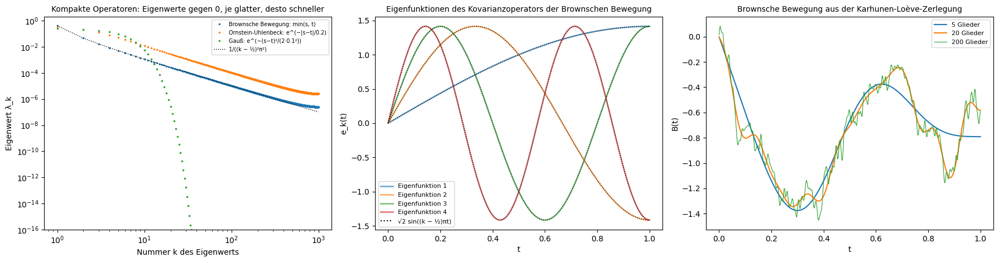

Brownsche Bewegung, Eigenwerte 1 … 4: [0.405285, 0.045032, 0.016211, 0.008271];  Formel: [0.405285, 0.045032, 0.016211, 0.008271]
Spur Σλ = 0.500000 (Theorie 1/2), Σλ² = 0.166667 (Theorie 1/6 = 0.166667)
Anteil der Varianz in den ersten 1, 5, 20 Gliedern: 0.8106, 0.9596, 0.9899  (8/π² = 0.8106)
Brownsche Bewegung: min(s, t)        λ₁ = 0.4053, λ₁₀/λ₁ = 2.77e-03, λ₃₀/λ₁ = 2.87e-04
Ornstein-Uhlenbeck: e^(−|s−t|/0.2)   λ₁ = 0.3309, λ₁₀/λ₁ = 3.58e-02, λ₃₀/λ₁ = 3.62e-03
Gauß: e^(−(s−t)²/(2·0.1²))           λ₁ = 0.2409, λ₁₀/λ₁ = 2.32e-02, λ₃₀/λ₁ = 7.03e-13


In [39]:
functional.compact_operators()

**39. Arten des Spektrums: Volterra, Multiplikation, Shift**

Eine Matrix hat nur Eigenwerte, ein Operator kann ein Spektrum ohne einen einzigen Eigenwert haben. Drei Beispiele: der Volterra-Operator (Integral von 0 bis x), die Multiplikation mit x und der Shift auf Folgen.

Der Volterra-Operator hat die Norm 2/π, aber ‖Vⁿ‖^(1/n) fällt gegen 0 (0.081 bei n = 30): Sein Spektrum ist nur die 0, und sie ist kein Eigenwert. Für die Multiplikation mit x gibt es zu 0.5 Funktionen mit beliebig kleinem Rest ‖(M − 0.5)ψ‖, aber keinen Eigenvektor: kontinuierliches Spektrum. Beim Rechtsshift ist S − λ für |λ| < 1 injektiv, aber sein Bild steht senkrecht auf einem festen Vektor: Residualspektrum.

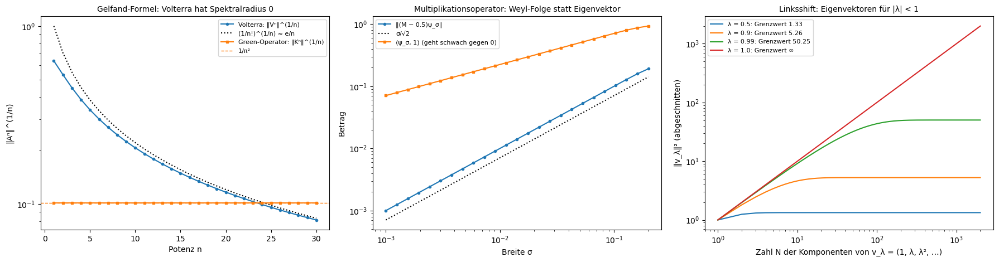

Volterra: ‖V‖ = 0.63662 (2/π = 0.63662), ‖V⁵‖ = 4.39e-03 ≤ 1/5! = 8.33e-03, ‖V³⁰‖^(1/30) = 0.0812
Green-Operator: ‖K³⁰‖^(1/30) = 0.10132 (1/π² = 0.10132); die Matrix-Eigenwerte des diskreten Volterra-Operators sind alle h/2 = 0.00125
Weyl-Folge: Rest bei σ = 0.001: 1.00e-03, Skalarprodukt mit 1: 7.08e-02
Rechtsshift, λ = 0.6: ⟨v_λ, (S − λ)x⟩ = 0.0e+00 für zufälliges x; ‖(S − λ)x‖/‖x‖ = 1.130 ≥ 1 − λ = 0.4


In [40]:
functional.spectrum_types()

**40. Endliche Abschnitte täuschen: Toeplitz-Operatoren und Pseudospektren**

Bei einem nicht normalen Operator verschieben kleine Störungen die Eigenwerte weit. Untersucht wird eine 60×60-Toeplitz-Matrix und ihr Pseudospektrum.

Die exakten Eigenwerte cos(kπ/61) liegen auf einer reellen Strecke, aber schon die Rundungsfehler von numpy verschieben sie um bis zu 0.04 ins Komplexe; Störungen von 10⁻¹⁰ schieben sie zur Ellipse des Symbols. Bei z = 0.5i, weit weg von allen Eigenwerten, ist z − T fast singulär (σ_min = 10⁻⁶). Folge: Die Potenzen einer solchen Matrix wachsen vorübergehend auf 1.7·10⁵, obwohl alle Eigenwerte kleiner als 1 sind; eine normale Matrix mit denselben Eigenwerten fällt sofort ab.

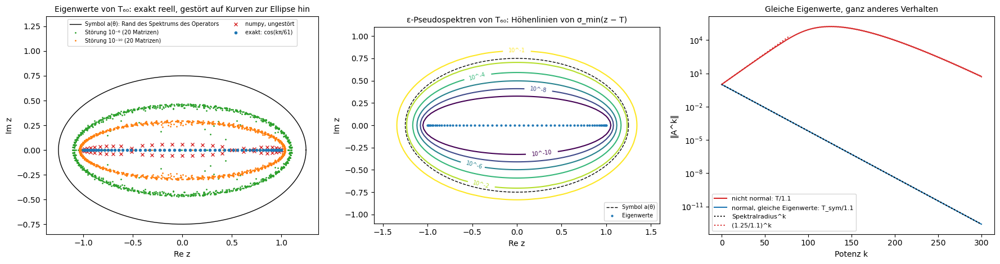

numpy-Eigenwerte von T₆₀: größter Imaginärteil 5.84e-02, größter Fehler gegen cos(kπ/61) 4.30e-02
Störung 1e-10: mittlerer Betrag 0.711, Median des Abstands zur Ellipse (relativ) 0.584, größter Imaginärteil 0.300
Störung 1e-06: mittlerer Betrag 0.800, Median des Abstands zur Ellipse (relativ) 0.441, größter Imaginärteil 0.468
nicht normal: T/1.1                    max ‖A^k‖ = 1.69e+05 bei k = 127, ‖A³⁰⁰‖ = 4.82e+00
normal, gleiche Eigenwerte: T_sym/1.1  max ‖A^k‖ = 1 bei k = 0, ‖A³⁰⁰‖ = 2.57e-13
σ_min(z − T₆₀) bei z = 0.5i (innerhalb der Ellipse, weit weg von allen Eigenwerten): 1.13e-06


In [41]:
functional.finite_sections()

**41. Spektralmaß: gebundene Zustände und Kontinuum**

Ein Potentialtopf hat gebundene Zustände und ein Kontinuum. Das Spektralmaß eines Wellenpakets sagt, welcher Anteil auf welchen Energien liegt; gerechnet wird in Kästen wachsender Länge.

Die drei gebundenen Energien −3.125, −1.125 und −0.125 bleiben bei jeder Kastenlänge, die übrigen Zustände rücken mit wachsender Länge immer dichter an null und werden zum Kontinuum. Das Paket liegt zu 58 % auf den gebundenen Zuständen und zu 42 % im Kontinuum. Der Kontinuumsanteil läuft davon: Für lange Zeiten bleibt genau die Überlebenswahrscheinlichkeit, die die gebundenen Zustände allein vorhersagen (0.132).

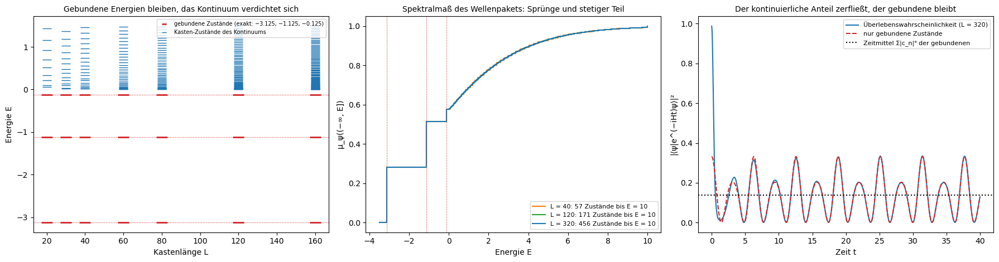

Gebundene Energien (L = 320): [-3.1251, -1.1253, -0.1252];  exakt [-3.125, -1.125, -0.125]
Gewicht des Pakets auf den gebundenen Zuständen: [0.2807, 0.2326, 0.0629], zusammen 0.5762;  Kontinuum 0.4174
L =  40: 57 Eigenwerte bis E = 10, kleinste positive Energie 0.0125, gebundenes Gewicht 0.5762
L = 120: 171 Eigenwerte bis E = 10, kleinste positive Energie 0.0014, gebundenes Gewicht 0.5762
L = 320: 456 Eigenwerte bis E = 10, kleinste positive Energie 0.0002, gebundenes Gewicht 0.5762
Überlebenswahrscheinlichkeit für t > 20: gemessen im Mittel 0.1318, nur gebunden 0.1316;  größte Abweichung 0.0035


In [42]:
functional.spectral_measure()

**42. Unbeschränkte Operatoren: Definitionsbereich und selbstadjungierte Erweiterungen**

Ein unbeschränkter Operator wie der Impuls −i d/dx ist erst mit Randbedingungen festgelegt. Verschiedene Randbedingungen ergeben verschiedene selbstadjungierte Operatoren mit verschiedenen Spektren.

Auf dem Ring mit der Phase θ ist das Spektrum des Impulses 2πℤ + θ; jede Phase gibt einen anderen Operator. Beim Laplace-Operator auf einem Intervall verschiebt die Robin-Bedingung den kleinsten Eigenwert von negativen Werten (ein Randzustand, −5.76) über 0 (Neumann) bis gegen π² (Dirichlet). Auf der Halbgeraden hat der Impuls gar keine selbstadjungierte Erweiterung: Eine Verschiebung schiebt das Paket über den Rand hinaus (Norm 0.003 nach a = 8), auf dem Ring bleibt die Norm 1.

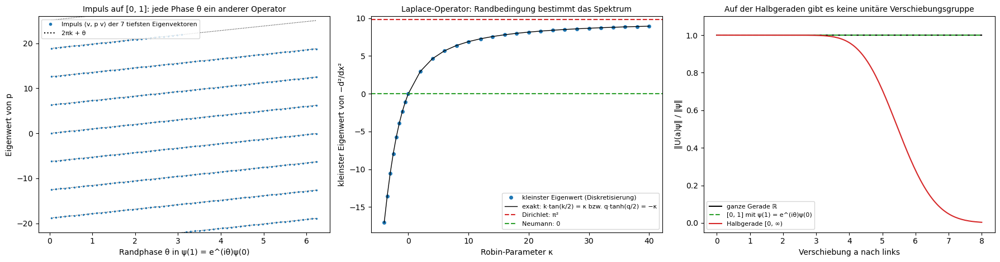

Diskretisierte Operatoren hermitesch für jedes θ (Fehler 0e+00); Impulse bei θ = 1.622: [-17.222, -10.943, -4.661, 1.622, 7.905, 14.185, 20.463], exakt [-17.228, -10.944, -4.661, 1.622, 7.905, 14.188, 20.472]
Robin κ =  -2.0: kleinster Eigenwert  -5.7569, exakt  -5.7569
Robin κ =   0.0: kleinster Eigenwert   0.0000, exakt   0.0000
Robin κ =   4.0: kleinster Eigenwert   4.6386, exakt   4.6386
Robin κ =  40.0: kleinster Eigenwert   8.9536, exakt   8.9536
Defektfunktionen e^(−x), e^(x): Norm² auf [0, 1] 0.4323 und 3.1945; auf [0, 30] 0.5000 und 5.71e+25
Verschiebung um a = 8: Norm auf der Halbgeraden 3.32e-03, auf dem Ring 1.000000


In [43]:
functional.unbounded_operators()

**43. Das Weyl-Gesetz: was man von einer Trommel hört**

Kann man die Form einer Trommel hören (Kac 1966)? Die Zahl der Eigenwerte unter λ wächst wie Fläche mal λ/4π (Weyl 1911); die Korrekturen enthalten den Umfang und die Ecken. Vier Formen: Quadrat, Kreis, Dreieck und L-Form.

Die Zählfunktion folgt der Weyl-Geraden mit einer Randkorrektur, die wie √λ wächst und den Umfang verrät. Aus der Wärmespur Σ e^(−λt) liest ein Fit Fläche, Umfang und den Eckenterm ab, für Quadrat, Kreis und Dreieck auf drei bis vier Stellen; die L-Form ist auf dem Gitter ungenauer (Umfang 4.66 statt 4.62). Ganz eindeutig ist die Antwort nicht: Es gibt verschiedene Trommeln mit gleichem Klang (Gordon, Webb und Wolpert 1992).

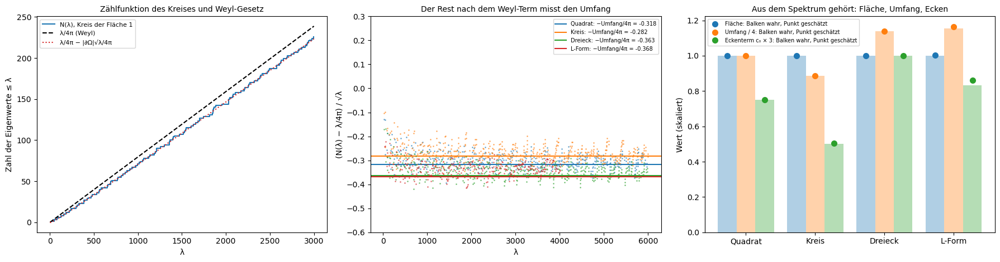

L-Form: 42721 Gitterpunkte, kleinster Eigenwert 28.9292 (Literatur für die L-Form aus Einheitsquadraten 9.6397, mal 3 = 28.919)
Form       Fläche (Fit / wahr)   Umfang (Fit / wahr)    c₀ (Fit / wahr)
Quadrat    1.0000 / 1.0000      4.0000 / 4.0000       0.2500 / 0.2500
Kreis      1.0000 / 1.0000      3.5453 / 3.5449       0.1681 / 0.1667
Dreieck    1.0000 / 1.0000      4.5590 / 4.5590       0.3333 / 0.3333
L-Form     1.0024 / 1.0000      4.6594 / 4.6188       0.2867 / 0.2778


In [44]:
functional.weyl_law()

**44. Der Satz von Stone: unitäre Gruppen und ihre Erzeuger**

Jede stetige Familie unitärer Operatoren mit U(s + t) = U(s)U(t) ist e^(−iHt) mit einem selbstadjungierten H (Stone 1932). Beispiele: Verschiebungen mit dem Impuls als Erzeuger und die Zeitentwicklung des Oszillators, die zur Fourier-Transformation wird.

Der Oszillator hat die Eigenwerte n + ½, und e^(−iπ/2·(H − ½)) ist die Fourier-Transformation (Abweichung 5·10⁻⁴); zweimal angewendet spiegelt sie f. Eine Verschiebung um a ändert eine glatte Funktion um etwa a, ein Rechteck um √a: Beides geht gegen null, die Gruppe ist stark stetig. Für eine schnell schwingende Funktion bleibt die Änderung 2, normstetig ist sie also nicht. Das Rechteck liegt nicht im Definitionsbereich des Impulses: Sein Differenzenquotient wächst wie √(2/a).

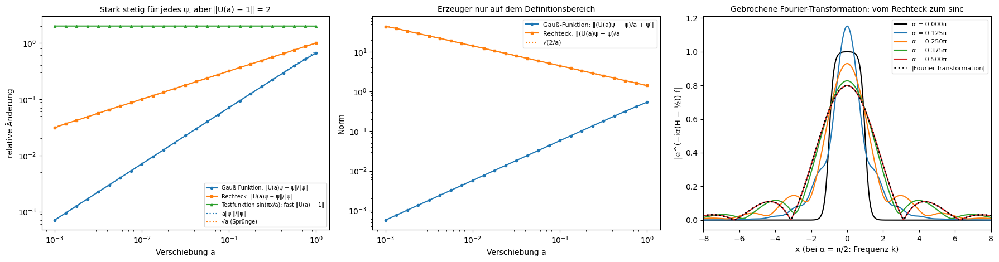

Oszillator auf dem Gitter: kleinste Eigenwerte [0.5, 1.5, 2.5, 3.5, 4.5], E₄₀ = 40.5000
e^(−iπ/2 (H − ½)) f gegen die Fourier-Transformation: größte Abweichung 4.5e-04;  α = π gibt f(−x): 1.2e-03
Verschiebung a = 1e-03: Gauß 7.07e-04, Rechteck 3.08e-02 (√a = 3.16e-02);  Testfunktion bei a = 0.01, 0.1, 1: [2.0, 1.9999, 1.9949]
Differenzenquotient bei a = 1e-03: Gauß-Fehler 5.76e-04, Rechteck 43.6 (√(2/a) = 44.7)


In [45]:
functional.stone_theorem()

**45. Stone-von Neumann: [x, p] = i hat keine Matrixdarstellung**

Die Vertauschungsrelation [x, p] = i lässt sich mit endlichen Matrizen nicht erfüllen, denn die Spur eines Kommutators ist null, die der Einheit nicht. Stone und von Neumann zeigten, dass es in unendlich vielen Dimensionen im Wesentlichen nur eine Darstellung gibt.

Mit abgeschnittenen Oszillator-Matrizen ist die Diagonale von [x, p]/i neunmal 1 und einmal −9: Der oberste Zustand gleicht die Spur aus. Die Weyl-Relation gilt auf dem Vakuum, solange die Photonenzahl klein gegen die Abschneidung ist. Die Eigenwerte von x_N sind genau die Knoten der Gauß-Hermite-Quadratur. In endlicher Dimension tritt das Weyl-Paar mit VU = ωUV an die Stelle, und auch dieses ist bis auf eine unitäre Transformation eindeutig (Fehler 7·10⁻¹⁵): die Takt- und Shift-Matrizen der Qudits.

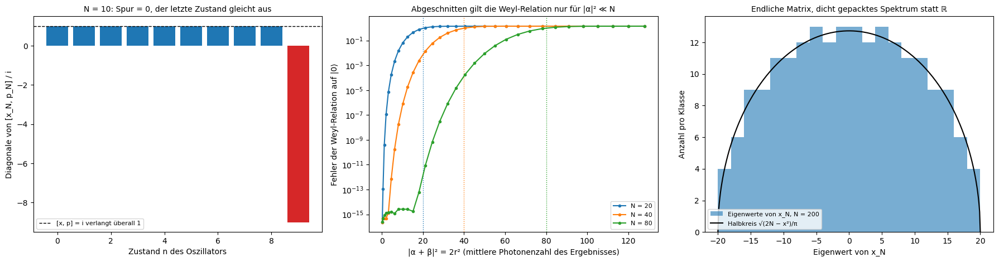

Diagonale von [x₁₀, p₁₀]/i: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, -9.0], Spur 0.0e+00
N = 20: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = 2.0, Fehler bei 2r² = 128: 1.417
N = 40: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = 10.1, Fehler bei 2r² = 128: 1.414
N = 80: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = 32.0, Fehler bei 2r² = 128: 1.414
Eigenwerte von x_N (N = 200) gleich den Hermite-Nullstellen (Gauß-Hermite-Knoten): 6.4e-14;  größter 19.339, √(2N) = 20.000
Endliches Weyl-Paar (N = 12), zufällig gedreht: VU = ωUV bis auf 4.4e-16;  rekonstruierte Verflechtung S mit S U S† = X, S V S† = Z: Fehler 6.8e-15


In [46]:
functional.stone_von_neumann()

**46. Der Koopman-Operator: nichtlineare Dynamik als lineare Abbildung**

Der Koopman-Operator wirkt nicht auf Zustände, sondern auf Messgrößen, und ist auch für nichtlineare Dynamik linear, allerdings unendlichdimensional. Die Dynamic Mode Decomposition (DMD) schätzt ihn aus Daten, hier für ein System mit einer schnellen und einer langsamen Rate.

Die Bahnen fallen schnell (Rate −1) auf eine Parabel und wandern dann langsam (−0.05) zum Ursprung. DMD mit den Koordinaten allein findet die langsame Rate, verfehlt aber die schnelle. Mit x₁² als zusätzlicher Messgröße (EDMD) wird das System exakt linear: Die Raten −1, −0.1 und −0.05 stimmen, und die Vorhersage über 20 Zeiteinheiten ist auf 10⁻¹⁰ genau statt um 1.7 falsch.

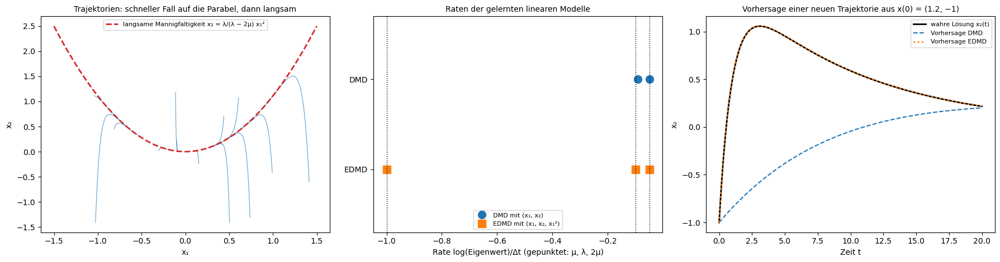

Raten DMD: [-0.0905, -0.05];  EDMD: [-1.0, -0.1, -0.05];  exakt: [-1.0, -0.1, -0.05]
Vorhersagefehler max |x₂| über t ∈ [0, 20]: DMD 1.681, EDMD 1.1e-10
EDMD-Matrix (gerundet):
[[0.995  0.     0.    ]
 [0.     0.9048 0.0947]
 [0.     0.     0.99  ]]


In [47]:
functional.koopman()

**47. Operator-Lernen: eine Abbildung zwischen Funktionsräumen aus Beispielen**

Gelernt wird eine Abbildung zwischen Funktionen, von der Anfangstemperatur zur Temperatur nach der Zeit T, aus 40 verrauschten Beispielpaaren. Das Modell ist ein Faktor je Frequenz im Fourier-Raum, ähnlich wie bei Fourier Neural Operators.

Der gelernte Faktor trifft e^(−k²T) bis k ≈ 10; darüber geht er im Rauschen unter, was kaum schadet, weil diese Frequenzen in der Lösung fehlen. Gelernt auf 64 Punkten, sagt das Modell auf 256 Punkten mit 4·10⁻⁴ Fehler vorher: Es lernt den Operator, nicht eine Matrix für ein Gitter. Mit 2 Beispielen ist sein Fehler schon 2.5·10⁻³; eine allgemeine Matrix erreicht das erst mit etwa 100.

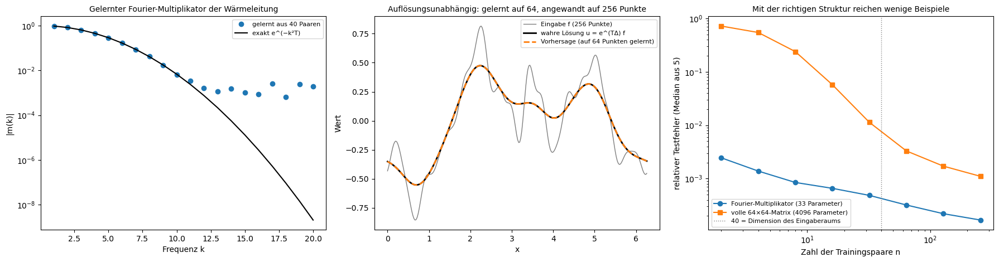

Multiplikator k = 1 … 5: [0.9513, 0.8187, 0.6375, 0.4491, 0.2866];  exakt [0.9512, 0.8187, 0.6376, 0.4493, 0.2865]
Fehler auf dem feinen Gitter (256 Punkte): 4.04e-04
Testfehler Multiplikator / Matrix: n = 2: 2.5e-03 / 7.2e-01, n = 4: 1.4e-03 / 5.5e-01, n = 8: 8.5e-04 / 2.4e-01, n = 16: 6.6e-04 / 5.8e-02, n = 32: 4.9e-04 / 1.1e-02, n = 64: 3.2e-04 / 3.3e-03, n = 128: 2.2e-04 / 1.7e-03, n = 256: 1.7e-04 / 1.1e-03


In [48]:
functional.operator_learning()

**48. Testfunktionen: zwei Bedeutungen**

Das Wort Testfunktion hat zwei Bedeutungen; gemeinsam ist die Idee, etwas Unbekanntes an etwas Bekanntem zu prüfen. In der Analysis sind es Funktionen, die beliebig glatt und außerhalb eines Intervalls exakt null sind, wie die Bump-Funktion Ψ(x) = e^(−1/(1 − x²)). Mit ihnen gibt man Knicken eine Ableitung und der Delta-Funktion einen Sinn, und man glättet, schaltet ein und aus und setzt lokale Stücke zusammen. In der Optimierung sind es Funktionen mit bekannten Minima, an denen man Verfahren vergleicht (Himmelblau, Rosenbrock, Rastrigin). Beide Arten tauchen am Ende in Quantenalgorithmen wieder auf.

Die Ausgabe gibt die Fläche unter der Bump-Funktion, ∫Ψ dx = 0.444, die man zum Normieren braucht.

In [49]:
testfunctions.why_testfunctions()

∫Ψ dx = 0.443994


**49. Die Bump-Funktion: glatt, aber nicht analytisch**

Ψ ist beliebig oft differenzierbar und trotzdem außerhalb von (−1, 1) null. Eine analytische Funktion könnte das nicht, denn ihre Taylor-Reihe am Rand wäre null und damit die ganze Funktion. sympy berechnet die Ableitungen bis zur Ordnung 12.

Alle Ableitungen gehen am Rand gegen null, aber erst sehr nahe daran: Bei h = 0.002 vor dem Rand ist die achte Ableitung 10⁻⁶⁹. Ψ(0.9) = 0.005 ist positiv, obwohl jede Taylor-Näherung um x = 1 null ergibt. Die Maxima der Ableitungen wachsen schneller als n!, die Taylor-Reihe hat also den Konvergenzradius null; geteilt durch (n!)² wachsen sie geometrisch mit dem Faktor 3.5 (Gevrey-Klasse 2).

Ψ^(n)(1 − h) geht gegen 0, aber erst sehr nahe am Rand:
  n = 1: h = 0.05: -7.02e-03   h = 0.01: -7.50e-19   h = 0.002: -2.60e-104
  n = 2: h = 0.05:  1.12e+00   h = 0.01:  3.60e-15   h = 0.002:  3.22e-99
  n = 4: h = 0.05:  7.58e+03   h = 0.01:  7.26e-08   h = 0.002:  4.83e-89
  n = 8: h = 0.05:  5.23e+11   h = 0.01:  1.55e+07   h = 0.002:  9.84e-69
Ψ(0.9) = 5.18e-03 > 0, obwohl jede Taylor-Näherung um x = 1 null ist
max|Ψ^(n)| / n!   für n = 0..12: 3.7e-01 8.0e-01 3.9e+00 3.1e+01 3.5e+02 5.0e+03 1.1e+05 2.9e+06 8.2e+07 2.6e+09 8.8e+10 3.5e+12 1.6e+14
max|Ψ^(n)| / (n!)² für n = 0..12: 3.7e-01 8.0e-01 1.9e+00 5.2e+00 1.4e+01 4.1e+01 1.6e+02 5.7e+02 2.0e+03 7.1e+03 2.4e+04 8.8e+04 3.4e+05
max|Ψ^(n)| / (n!)² wächst geometrisch mit dem Faktor C ≈ 3.54 pro Ordnung (Gevrey-Klasse 2)


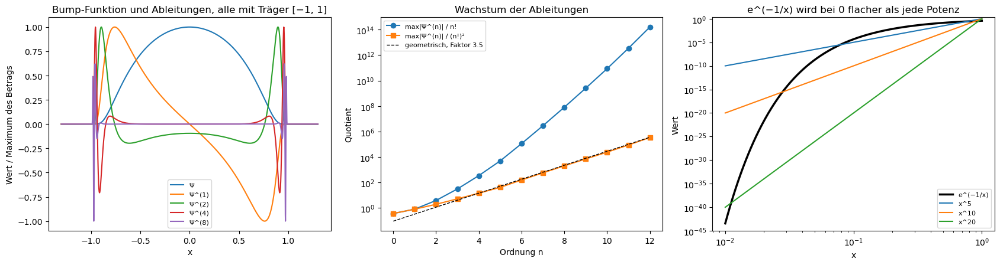

In [50]:
testfunctions.bump_function()

**50. Bausteine: glatter Übergang, Plateau, Zerlegung der Eins**

Aus Ψ baut man einen glatten Übergang S von 0 nach 1, ein Plateau, das auf einem Intervall genau 1 ist, und eine Zerlegung der Eins aus verschobenen Bausteinen.

S ist für x ≤ 0 exakt 0 und für x ≥ 1 exakt 1, mit S(x) + S(1 − x) = 1; alle Ableitungen beginnen und enden flach, es gibt keine Ecken. Das Plateau ist genau 1 auf [−1, 1] und genau 0 außerhalb von (−2, 2). Die Bausteine der Zerlegung summieren sich überall auf 1 (bis auf 2·10⁻¹⁶), und an jeder Stelle sind nur ein oder zwei von ihnen ungleich null: So setzt man lokale Konstruktionen zu globalen zusammen.

S(0.5) = 0.500; größte Abweichung von S(x) + S(1 − x) = 1: 2.2e-16
S = 0 für alle x ≤ 0: True;  S = 1 für alle x ≥ 1: True
Plateau: genau 1 auf [−1, 1]: True;  genau 0 außerhalb von (−2, 2): True
Zerlegung der Eins auf [−3, 3]: größte Abweichung |Σχ_k − 1| = 2.2e-16; an jeder Stelle 1 bis 2 Terme ungleich 0


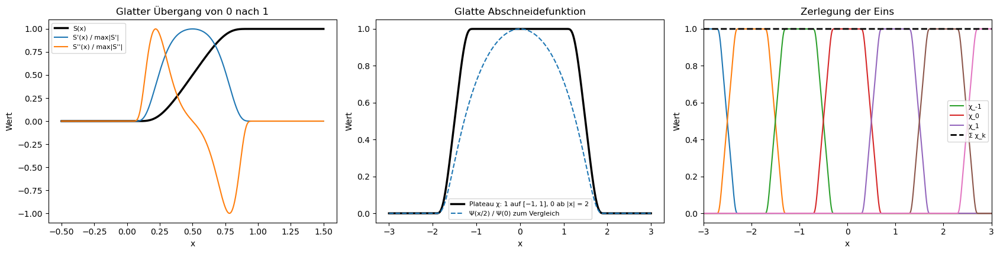

In [51]:
testfunctions.building_blocks()

**51. Glätten mit einem Mollifier**

Die Faltung mit einem schmalen Glättungskern der Breite ε macht jede Funktion glatt und ändert sie nur in der Nähe ihrer Knicke und Sprünge. Geglättet werden |x|, ein Kasten und eine zackige Funktion vom Weierstraß-Typ.

Bei |x| wird nur das Fenster (−ε, ε) um den Knick abgerundet; außerhalb bleibt die Funktion exakt gleich, weil ein symmetrischer Kern lineare Funktionen nicht ändert. Der größte Fehler ist genau 0.334·ε und halbiert sich mit ε. Beim Kasten werden die Sprünge zu glatten Flanken, und der Träger wächst um ε auf jeder Seite.

m1 = ∫|z| φ(z) dz = 0.33445


ε = 0.4000: max|u_ε − |x|| = 0.13378 bei x = +0.0000 (ε·m1 = 0.13378);  L1-Fehler Kasten 0.26736 (2ε·m1 = 0.26756);  Träger [-1.3996, 1.3996]
ε = 0.2000: max|u_ε − |x|| = 0.06689 bei x = +0.0000 (ε·m1 = 0.06689);  L1-Fehler Kasten 0.13358 (2ε·m1 = 0.13378);  Träger [-1.1998, 1.1998]
ε = 0.1000: max|u_ε − |x|| = 0.03345 bei x = +0.0000 (ε·m1 = 0.03345);  L1-Fehler Kasten 0.06669 (2ε·m1 = 0.06689);  Träger [-1.0998, 1.0998]
ε = 0.0500: max|u_ε − |x|| = 0.01672 bei x = +0.0000 (ε·m1 = 0.01672);  L1-Fehler Kasten 0.03325 (2ε·m1 = 0.03345);  Träger [-1.0498, 1.0498]
ε = 0.0250: max|u_ε − |x|| = 0.00836 bei x = +0.0000 (ε·m1 = 0.00836);  L1-Fehler Kasten 0.01652 (2ε·m1 = 0.01672);  Träger [-1.0248, 1.0248]
ε = 0.0125: max|u_ε − |x|| = 0.00418 bei x = +0.0000 (ε·m1 = 0.00418);  L1-Fehler Kasten 0.00816 (2ε·m1 = 0.00836);  Träger [-1.0124, 1.0124]
(Der numerische Träger ist etwas kleiner als [−1 − ε, 1 + ε], weil e^(−1/(1−z²)) nahe |z| = 1 unter die kleinste darstellbare Zahl fällt.)


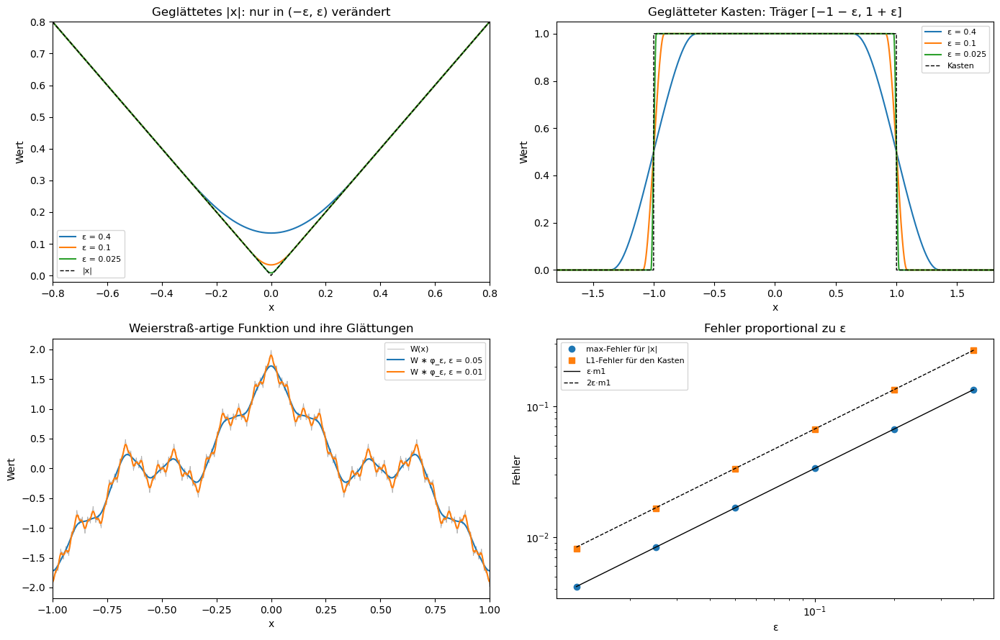

In [52]:
testfunctions.mollifier()

**52. Distributionen: schwache Ableitungen und δ als Grenzwert**

Eine Distribution ist durch das festgelegt, was sie mit Testfunktionen macht: ⟨δ, φ⟩ = φ(0). Die Ableitung schiebt man per partieller Integration auf die Testfunktion; so bekommen Sprung und Knick eine Ableitung. Dazu schmale Kerne, die gegen δ gehen.

Für vier zufällige Testfunktionen ist −∫Hφ′ = φ(0), −∫|x|φ′ = ∫sign·φ und −∫sign·φ′ = 2φ(0), auf sieben Stellen: Die schwachen Ableitungen von Stufe, Betrag und Vorzeichen sind δ, sign und 2δ. Schmaler werdende Kerne φ_ε gehen gegen δ, der Fehler fällt wie ε², obwohl ihre L²-Norm wächst: Die Konvergenz gibt es nur im schwachen Sinn.

                      −∫Hφ'        φ(0)      −∫|x|φ'    ∫sign·φ    −∫sign·φ'     2φ(0)
c = -0.32, r = 1.57:   0.3521254  0.3521254   -0.1964402 -0.1964402    0.7042508  0.7042508
c = -0.15, r = 1.75:   0.3653382  0.3653382    0.3531796  0.3531796    0.7306765  0.7306765
c = +0.15, r = 1.16:   0.3614190  0.3614190    0.3575350  0.3575350    0.7228380  0.7228380
c = +0.14, r = 1.70:   0.3655311  0.3655311    0.1897230  0.1897230    0.7310621  0.7310621

⟨φ_ε, g⟩ − g(0) mit g = cos x + x³ (Vorhersage −ε²m2/2, m2 = 0.15811):
  ε =  0.50: -1.963e-02   Vorhersage -1.976e-02   Norm ‖φ_ε‖₂ =   1.162
  ε =  0.20: -3.159e-03   Vorhersage -3.162e-03   Norm ‖φ_ε‖₂ =   1.837
  ε =  0.10: -7.903e-04   Vorhersage -7.906e-04   Norm ‖φ_ε‖₂ =   2.598
  ε =  0.05: -1.976e-04   Vorhersage -1.976e-04   Norm ‖φ_ε‖₂ =   3.675
  ε =  0.02: -3.162e-05   Vorhersage -3.162e-05   Norm ‖φ_ε‖₂ =   5.810
  ε =  0.01: -7.906e-06   Vorhersage -7.906e-06   Norm ‖φ_ε‖₂ =   8.217

Sokhotski–Plemelj für die erste Testfunk

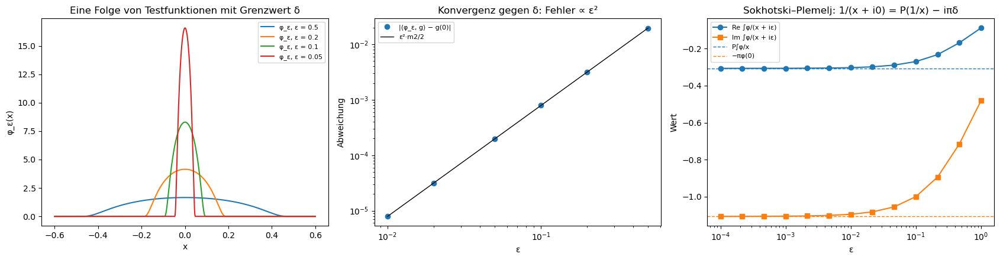

In [53]:
testfunctions.distributions()

**53. Eine schwache Lösung der Wellengleichung**

Eine Welle mit Knicken, u = F(x − t), hat an den Knicken keine zweite Ableitung und löst die Wellengleichung trotzdem, im schwachen Sinn: ⟨u, □φ⟩ = 0 für jede Testfunktion φ.

Für die Geschwindigkeit c = 1 ist ⟨u, □φ⟩ für fünf Testfunktionen, die die Knicke überdecken, null bis auf 10⁻¹⁶, obwohl die Integranden die Größe 1 haben. Für c = 2 ist u keine Lösung, und die Integrale treffen den vorhergesagten Wert ungleich null. Schwache Lösungen braucht man für Stoßwellen, die nirgends glatt bleiben.

c = 1: φ um (+0.68, 0.95), r = 1.04:  ⟨u, □φ⟩ = +2.654e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 0.943)
c = 1: φ um (+0.64, 0.73), r = 1.17:  ⟨u, □φ⟩ = +1.138e-17   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 0.667)
c = 1: φ um (+1.10, 1.16), r = 0.81:  ⟨u, □φ⟩ = +1.655e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 1.283)


c = 1: φ um (+0.98, 0.87), r = 0.94:  ⟨u, □φ⟩ = -3.100e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 1.013)
c = 1: φ um (+0.59, 0.94), r = 1.01:  ⟨u, □φ⟩ = -1.987e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 1.059)
c = 2: φ um (+2.88, 1.37), r = 1.36:  ⟨u, □φ⟩ = -3.058e-01   Vorhersage -3.058e-01   (Größe ∫|u □φ| = 0.421)


c = 2: φ um (+1.77, 0.85), r = 1.46:  ⟨u, □φ⟩ = -2.847e-01   Vorhersage -2.847e-01   (Größe ∫|u □φ| = 0.390)
c = 2: φ um (+1.65, 0.93), r = 1.43:  ⟨u, □φ⟩ = -2.901e-01   Vorhersage -2.901e-01   (Größe ∫|u □φ| = 0.400)
c = 2: φ um (+2.11, 1.20), r = 1.02:  ⟨u, □φ⟩ = -3.953e-01   Vorhersage -3.953e-01   (Größe ∫|u □φ| = 0.586)


c = 2: φ um (+2.39, 1.20), r = 0.96:  ⟨u, □φ⟩ = -4.267e-01   Vorhersage -4.267e-01   (Größe ∫|u □φ| = 0.607)


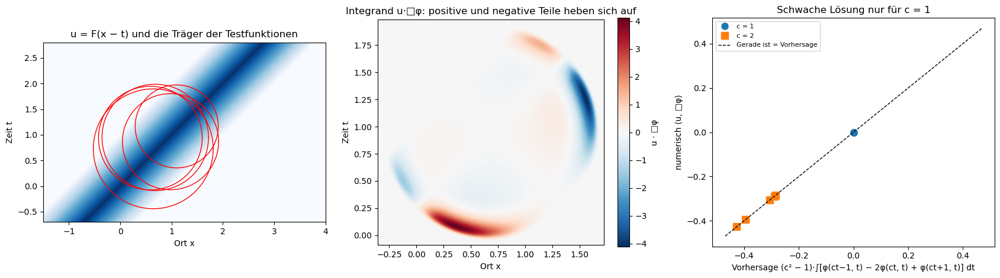

In [54]:
testfunctions.weak_solution()

**54. Fourier-Abfall: von 1/k bis e^(−√k)**

Wie schnell die Fourier-Transformierte fällt, verrät die Glattheit (Schritt 17). Verglichen werden Rechteck, Dreieck, Hann-Fenster, Gauß-Funktion und die Bump-Funktion.

Rechteck, Dreieck und Hann fallen wie 1/k, 1/k² und 1/k³, die Gauß-Funktion wie e^(−k²/4). Die Bump-Funktion liegt dazwischen: schneller als jede Potenz, aber langsamer als exponentiell, wie k^(−3/4)·e^(−√k); eine Sattelpunkt-Rechnung trifft das bis k = 700 auf wenige Prozent. Schneller geht es mit kompaktem Träger nicht: Fiele die Transformierte exponentiell, wäre die Funktion analytisch und damit überall null.

Rechteck (Sprung) : geschlossene Formel gegen numerisches Integral, größte Abweichung 2.2e-16
Dreieck (Knick)   : geschlossene Formel gegen numerisches Integral, größte Abweichung 1.1e-16
Hann cos²(πx/2)   : geschlossene Formel gegen numerisches Integral, größte Abweichung 5.2e-17
Gauß e^(−x²)       : bei k = 3 numerisch 0.1868152615, Formel 0.1868152615


Kontrolle: Ψ̂(0) = 0.44399382 = ∫Ψ = 0.44399382

   k    Ψ̂(k) numerisch   Sattelpunkt     Verhältnis   Rechteck-Hülle 2/k
  25.0  +1.4342e-03   +1.3987e-03     1.0254     8.0e-02
  50.0  -6.6517e-05   -6.4251e-05     1.0353     4.0e-02
 100.0  +2.2366e-06   +2.1829e-06     1.0246     2.0e-02
 200.0  -2.4641e-08   -2.4576e-08     1.0026     1.0e-02
 400.0  -1.3566e-11   -1.3776e-11     0.9847     5.0e-03
 700.0  +5.5327e-14   +5.5052e-14     1.0050     2.9e-03


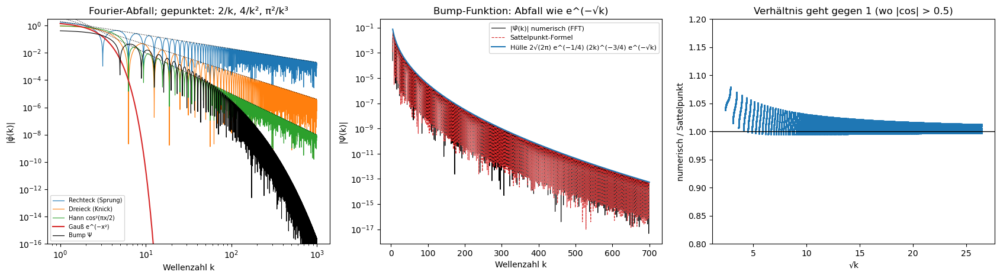

In [55]:
testfunctions.fourier_decay()

**55. Galerie: zwölf Benchmark-Funktionen der Optimierung**

In der Optimierung prüft man Verfahren an Funktionen, deren Minima man kennt. Zwölf klassische Beispiele, von der einfachen Schüssel bis zu Landschaften mit sehr vielen Mulden.

Booth ist eine schräge Schüssel, Rosenbrock ein gekrümmtes Tal, Himmelblau hat vier Mulden, Rastrigin ein Gitter aus Mulden, Easom eine Ebene mit einer einzigen Nadel. Für alle zwölf findet eine Suche die Minima aus der Literatur, mit einem Gradienten nahe null.

Funktion           Tabelle f*        f(x*)   |∇f(x*)|  beste Suche   gefunden bei
Booth                 0.00000      0.00000    0.0e+00      0.00000   (1.0000, 3.0000)
Rosenbrock            0.00000      0.00000    6.4e-09      0.00000   (1.0000, 1.0000)
Beale                 0.00000      0.00000    3.1e-09      0.00000   (3.0000, 0.5000)
Himmelblau            0.00000      0.00000    4.2e-05      0.00000   (3.0000, 2.0000)


Six-Hump Camel       -1.03160     -1.03163    9.2e-04     -1.03163   (-0.0898, 0.7127)
Goldstein–Price       3.00000      3.00000    1.3e-08      3.00000   (0.0000, -1.0000)
Styblinski–Tang     -78.33234    -78.33233    1.4e-06    -78.33233   (-2.9035, -2.9035)
Rastrigin             0.00000      0.00000    0.0e+00      0.00000   (0.0000, 0.0000)


Ackley                0.00000      0.00000    0.0e+00      0.00000   (0.0000, 0.0000)
Easom                -1.00000     -1.00000    0.0e+00     -1.00000   (3.1416, 3.1416)
Schwefel              0.00000      0.00003    1.7e-05      0.00003   (420.9687, 420.9687)
Eggholder          -959.64070   -959.64066    3.4e+00   -959.64066   (512.0000, 404.2318)

Schwefel, eine Koordinate: die drei tiefsten lokalen Minima bei x = 420.97 (Wert -418.98), -302.52 (Wert -300.54), 203.81 (Wert -201.84)


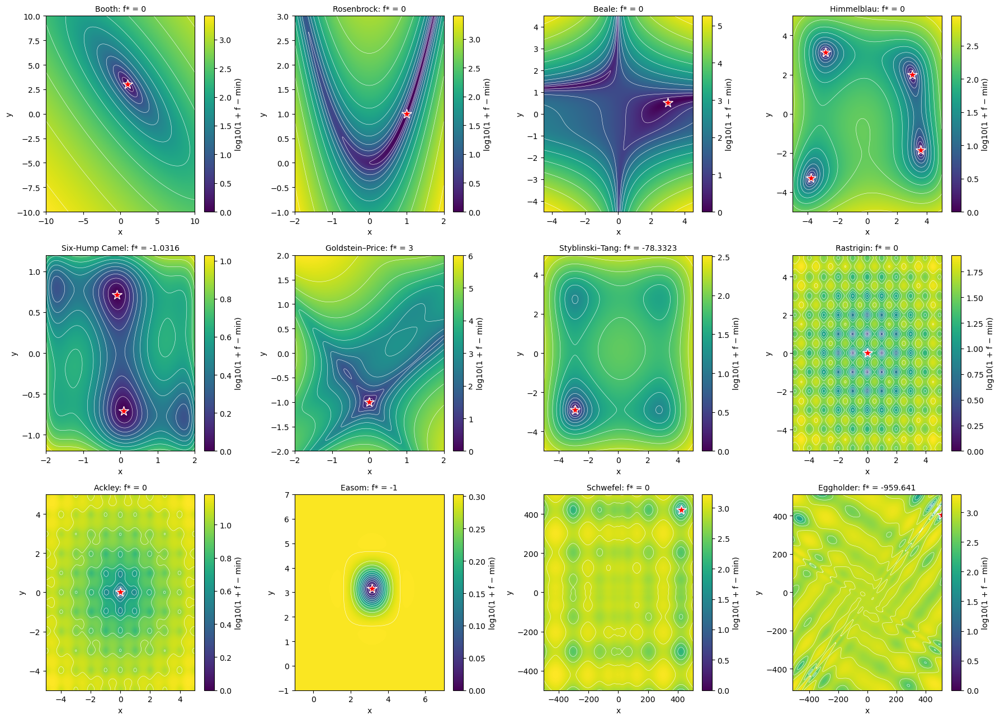

In [56]:
testfunctions.gallery()

**56. Himmelblau und Rosenbrock aus der Nähe**

Zwei der Funktionen genauer, mit logarithmischer Farbskala, weil ihre Werte über viele Größenordnungen reichen.

Himmelblau hat vier Mulden mit f = 0, vier Pässe und ein flaches Maximum in der Mitte. Bei Rosenbrock ist die Talsohle fast flach: Entlang y = x² fällt f nur von 4 auf 0, quer dazu ist es 0.5 neben der Sohle schon 25. Deshalb findet ein Verfahren das Tal schnell und das Minimum darin langsam.

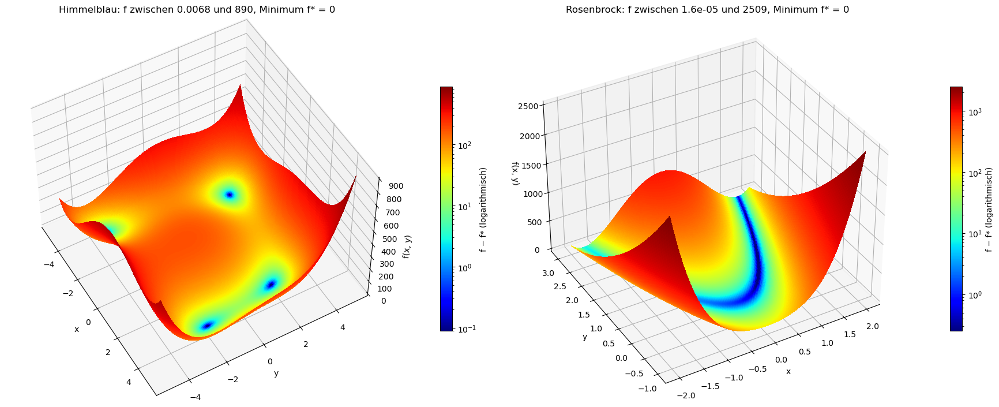

Rosenbrock entlang der Talsohle y = x²: f(−1, 1) = 4, f(0, 0) = 1, f(0.5, 0.25) = 0.25, f(1, 1) = 0
Rosenbrock quer zum Tal, 0.5 neben der Sohle: f(0.5, 0.75) = 25.2


In [57]:
testfunctions.gallery_contours()

**57. Die zwölf Funktionen als Landschaften**

Dieselben zwölf Funktionen als Flächen. Bei den Funktionen mit wenigen Minima ist die Farbe logarithmisch, bei den fünf mit vielen Minima linear.

Rastrigin sieht aus wie ein Eierkarton, Ackley wie ein Trichter mit gewellter Oberfläche. Easom ist fast überall eine Ebene: Dort ist der Gradient praktisch null, und kein Verfahren bekommt einen Hinweis, wo die Nadel liegt.

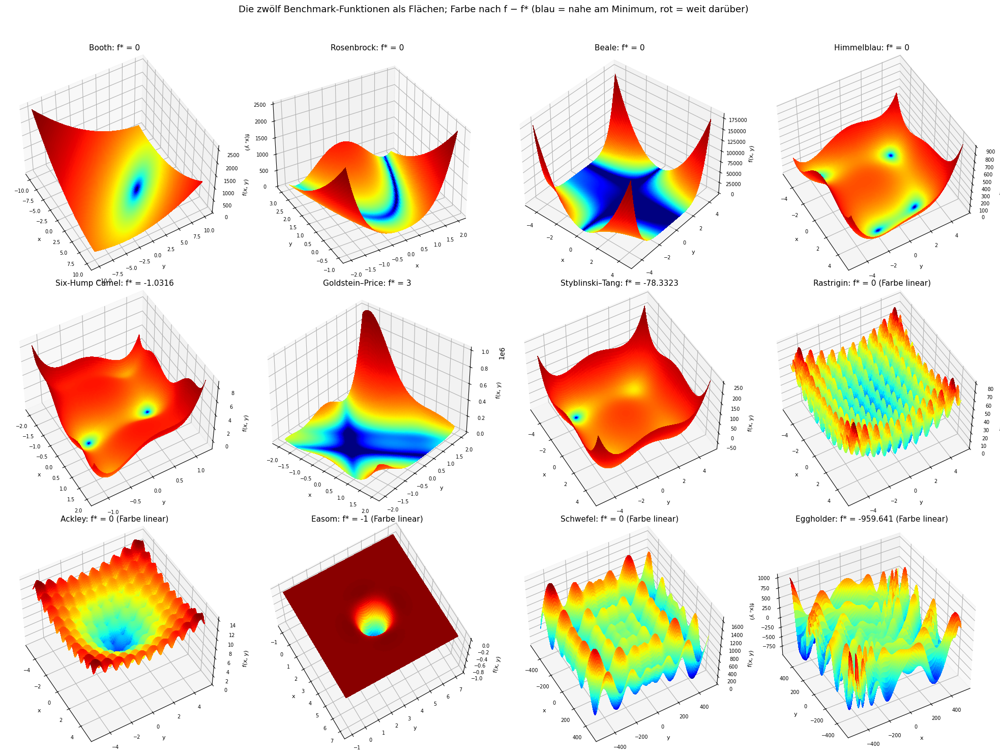

In [58]:
testfunctions.gallery_landscapes()

**58. Himmelblau: vier Minima, neun kritische Punkte**

Wie viele kritische Punkte hat Himmelblau, und wohin laufen Gradientenabstieg und Newton-Verfahren? sympy findet alle kritischen Punkte über eine Resultante.

Es gibt neun: vier Minima, vier Sattelpunkte und ein Maximum, und 4 − 4 + 1 = 1 ist die Euler-Charakteristik der Ebene (Poincaré-Hopf). Der Gradientenabstieg teilt die Ebene in vier fast gleich große Einzugsgebiete, deren Grenzen durch die Sattelpunkte laufen. Das Newton-Verfahren sucht nur Nullstellen des Gradienten: Es endet in 58 % der Fälle in einem Minimum, in 36 % in einem Sattel und in 6 % im Maximum.

Faktorisierung: (x - 3)*(x**3 + 3*x**2 - 13*x - 38)
Resultante von f_x und f_y bezüglich y: Grad 9, reelle Nullstellen: 9

         x          y           f   Typ
 -3.779310  -3.283186    0.000000   Minimum
 -2.805118   3.131313    0.000000   Minimum
  3.000000   2.000000    0.000000   Minimum
  3.584428  -1.848127    0.000000   Minimum
 -3.073026  -0.081353  104.015163   Sattel
 -0.127961  -1.953715  178.337239   Sattel
  0.086678   2.884255   67.719150   Sattel
  3.385154   0.073852   13.311926   Sattel
 -0.270845  -0.923039  181.616522   Maximum
Poincaré–Hopf: #Min − #Sattel + #Max = 4 − 4 + 1 = 1



Gradientenabstieg: Anteile der vier Minima: 0.237, 0.260, 0.256, 0.247 | nicht entschieden: 0.0000
Newton endet in einem Minimum : 0.579
Newton endet in einem Sattel  : 0.359
Newton endet in einem Maximum : 0.061
Newton ohne Konvergenz in 60 Schritten: 0.0000


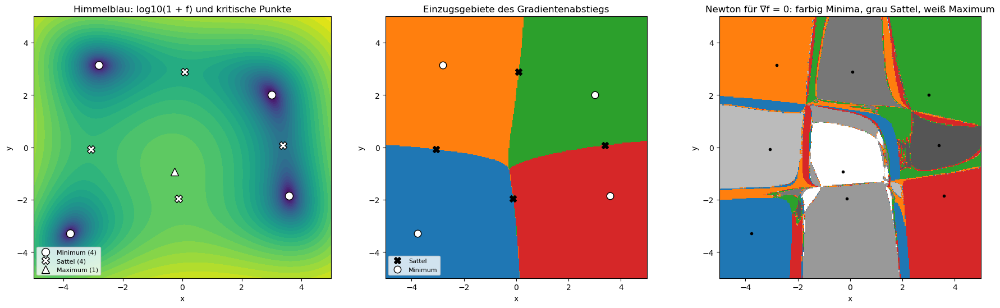

In [59]:
testfunctions.himmelblau_minima()

**59. Rosenbrock: das gekrümmte Tal**

Im Minimum von Rosenbrock ist die Krümmung quer zum Tal 2500-mal so groß wie längs. Verglichen werden Gradientenabstieg, Momentum, Adam, Newton, Nelder-Mead und BFGS.

Der Gradientenabstieg ist nur für Schrittweiten unter 2/λ_max = 0.002 stabil und braucht dann 34 374 Schritte, wie die Vorhersage ln(10⁶)/(η·λ_min) = 34 594; mit η = 0.002 konvergiert er nicht mehr. Momentum braucht 3241 Schritte, Adam 5559, BFGS 34 Iterationen und Newton 6 Schritte. Wer die Krümmung kennt, gleicht die schlechte Kondition aus; das ist der Vorteil der Verfahren zweiter Ordnung.

Hesse-Matrix bei (1, 1): Eigenwerte 1001.60 und 0.3994, Kondition 2508, Stabilitätsgrenze 2/λmax = 0.001997


Gradient η = 0.001          :   34374 Schritte, konvergiert, Abstand am Ende 1.0e-06


Gradient η = 0.002          :  200000 Schritte, nicht konvergiert, Abstand am Ende 2.7e-03
Momentum η = 0.001, β = 0.9 :    3241 Schritte, konvergiert, Abstand am Ende 1.0e-06
Adam lr = 0.01              :    5559 Schritte, konvergiert, Abstand am Ende 1.0e-06
Newton                      :       6 Schritte, konvergiert, Abstand am Ende 1.9e-11
Vorhersage für den Gradientenabstieg mit η = 0.001: ln(1e6)/(η λmin) = 34594 Schritte
Nelder-Mead                 :     132 Iterationen, 249 Funktionsauswertungen, Abstand am Ende 5.4e-11
BFGS                        :      34 Iterationen, 41 Funktionsauswertungen und 41 Gradienten, Abstand am Ende 1.2e-12


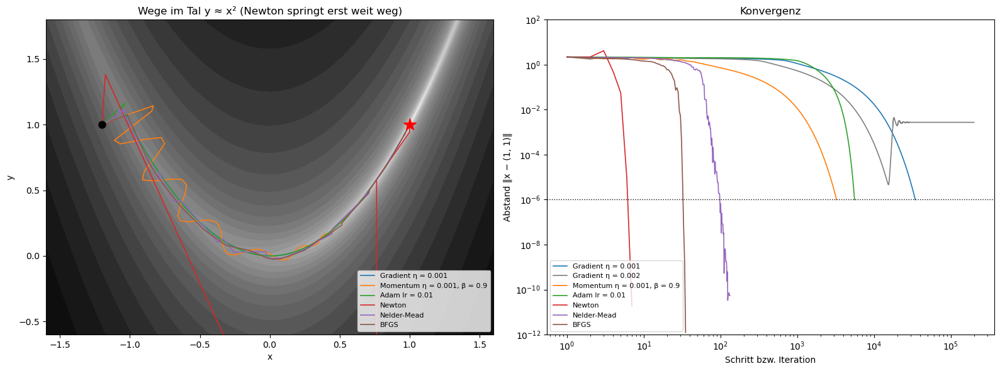

In [60]:
testfunctions.rosenbrock_valley()

**60. Viele lokale Minima: Rastrigin und Ackley**

Rastrigin hat im Suchbereich 11 Mulden pro Richtung, in d Dimensionen also 11^d. Wie oft trifft ein lokales Verfahren aus einem zufälligen Start das globale Minimum, und was leisten globale Verfahren in zehn Dimensionen?

Die Trefferquote fällt wie p₁^d mit p₁ = 0.098: 0.0094 bei d = 2, 0.00009 bei d = 4, bei d = 5 kein Treffer in 100 000 Starts. In zehn Dimensionen bleiben Multistart und Basin-Hopping bei Werten von 3 bis 29 hängen; Dual Annealing löst beide Funktionen in allen Läufen.

Rand des Einzugsgebiets von 0: b = 0.50255, p1 = 2b/10.24 = 0.09815
d = 1: Erfolg 9.77e-02 (Vorhersage p1^d = 9.82e-02, 100000 Starts); verschiedene lokale Minima gefunden: 11 (11^d = 11)


d = 2: Erfolg 9.43e-03 (Vorhersage p1^d = 9.63e-03, 100000 Starts); verschiedene lokale Minima gefunden: 121 (11^d = 121)


d = 3: Erfolg 8.40e-04 (Vorhersage p1^d = 9.46e-04, 100000 Starts); verschiedene lokale Minima gefunden: 1331 (11^d = 1331)


d = 4: Erfolg 9.00e-05 (Vorhersage p1^d = 9.28e-05, 100000 Starts)


d = 5: Erfolg 0.00e+00 (Vorhersage p1^d = 9.11e-06, 100000 Starts)

d = 10, je drei Läufe:


  Rastrigin Multistart (100 × L-BFGS-B) : beste Werte  11.9395,  27.8588,  28.8538;  Erfolge 0/3;  Auswertungen im Mittel     20680


... (3 outputs left out)

  Ackley    Multistart (100 × L-BFGS-B) : beste Werte  15.5067,  18.0311,  18.1880;  Erfolge 0/3;  Auswertungen im Mittel     16203


  Ackley    Basin-Hopping (100 Sprünge) : beste Werte  19.6559,  19.5454,  19.3289;  Erfolge 0/3;  Auswertungen im Mittel     17409


  Ackley    Dual Annealing              : beste Werte   0.0000,   0.0000,   0.0000;  Erfolge 3/3;  Auswertungen im Mittel     22571


  Ackley    Differential Evolution      : beste Werte   0.0000,   0.0000,   0.0000;  Erfolge 3/3;  Auswertungen im Mittel     69681


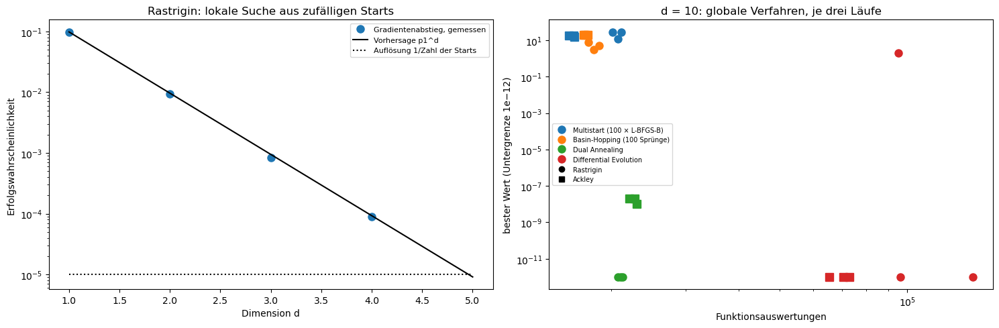

In [61]:
testfunctions.many_minima()

**61. Fair vergleichen: Verschieben und Drehen**

Standard-Rastrigin hat sein Minimum im Mittelpunkt und ist separierbar: Jede Koordinate lässt sich einzeln optimieren. Manche Verfahren nutzen das aus, ohne es zu sagen. Deshalb wird die Funktion verschoben und gedreht.

Auf der Standardfunktion lösen alle vier Verfahren das Problem. Verschoben scheitert der Start in der Mitte; gedreht scheitern Differential Evolution und Dual Annealing, die die Separierbarkeit ausnutzen; verschoben und gedreht scheitern alle vier. Ein Teil des Erfolgs auf der Standardfunktion kommt also von der Lage des Minimums und nicht vom Verfahren; deshalb vergleicht man an verschobenen und gedrehten Funktionen.

Standard             : Koordinatensuche 0;  L-BFGS-B aus der Mitte 0;  Differential Evolution 0, 0, 1.99;  Dual Annealing 4.26e-14, 2.84e-14, 5.68e-14


verschoben           : Koordinatensuche 8.53e-14;  L-BFGS-B aus der Mitte 58.7;  Differential Evolution 0, 0, 0;  Dual Annealing 5.68e-14, 8.53e-14, 4.26e-14


gedreht              : Koordinatensuche 0;  L-BFGS-B aus der Mitte 0;  Differential Evolution 4.97, 12.9, 5.97;  Dual Annealing 36.8, 26.9, 10.9


verschoben + gedreht : Koordinatensuche 29.8;  L-BFGS-B aus der Mitte 35.8;  Differential Evolution 6.96, 11.9, 9.95;  Dual Annealing 24.9, 41.9, 33.8


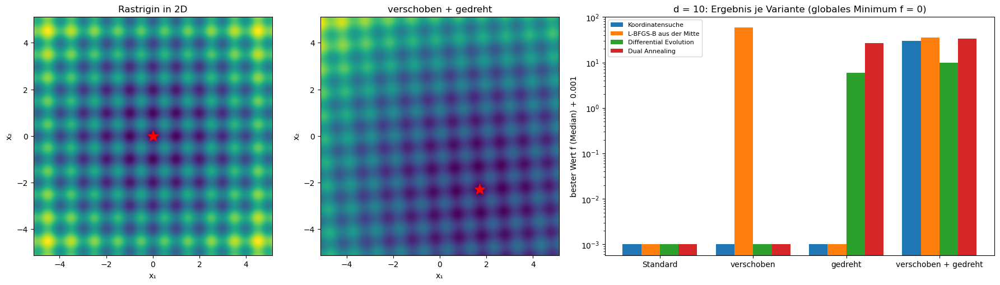

In [62]:
testfunctions.fair_comparison()

**62. Phasenschätzung mit Fenster**

Die Quanten-Phasenschätzung endet mit einer Fourier-Transformation über ein Register, und wie in Schritt 26 verschmiert ein abgeschnittenes Rechteck die Spitze. Ein glattes Fenster im Anfangszustand des Registers unterdrückt die Ausläufer: eine Testfunktion der Analysis im Quantenalgorithmus.

Beim Rechteck liegt die Wahrscheinlichkeit, um mehr als 100 Gitterpunkte daneben zu liegen, bei 1.6·10⁻³, wie die Formel 2 sin²(πNθ)/(π²k) vorhersagt. Mit dem Sinus-Fenster ist der mittlere Fehler am kleinsten (0.5/N statt 10.7/N), mit der Bump-Funktion fallen die Ausläufer am schnellsten (6·10⁻¹⁸ bei k = 100). Das Kaiser-Fenster ist am Rand nicht genau null und fällt deshalb für große k nur wie 1/k.

Fenster                   Σ P   RMS·N  P(|Fehler|>1)  P(|Fehler|>5) P(|Fehler|>20) P(|Fehler|>100)
Rechteck (Standard)  1.000000  10.721       1.54e-01       3.23e-02       8.09e-03       1.57e-03
Sinus                1.000000   0.500       6.54e-03       5.38e-05       8.76e-07       1.35e-08
Hann                 1.000000   0.577       5.06e-02       7.05e-06       6.76e-09       2.17e-12
Kaiser β = 10        1.000000   0.723       1.43e-01       1.08e-08       2.81e-09       6.31e-10
Bump                 1.000000   0.558       2.00e-02       1.09e-04       6.43e-09       5.75e-18
Rechteck bei k = 20 und 100: gemessen 8.085e-03, 1.568e-03; Vorhersage 2 sin²(πNθ)/(π²k) = 8.097e-03, 1.619e-03
Kaiser-Fenster am Rand: 3.6e-04 (relativ zur Mitte, nicht exakt 0)


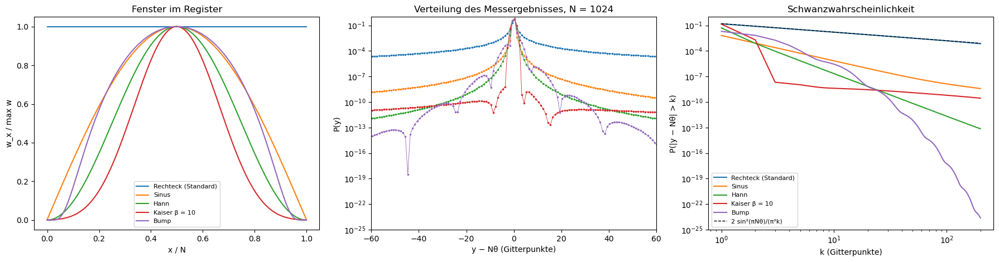

In [63]:
testfunctions.windowed_phase_estimation()

**63. Adiabatische Zeitpläne**

Beim adiabatischen Rechnen ändert man einen Hamilton-Operator langsam über die Zeit T. Die Fehlerwahrscheinlichkeit hängt davon ab, wie glatt der Zeitplan an Anfang und Ende ist. Verglichen werden ein linearer, ein kubischer, ein quintischer und ein beliebig glatter Zeitplan aus dem Baustein S.

Linear fällt der Fehler wie T⁻², kubisch wie T⁻⁴, quintisch wie T⁻⁶ (gemessen −2.01, −4.00, −6.05): Jede Ableitung, die an den Enden verschwindet, bringt zwei Potenzen. Der glatte Zeitplan fällt schneller als jede Potenz, wie e^(−4√T), und erreicht bei T = 250 den Wert 10⁻²⁵, während der lineare dort bei 10⁻⁵ liegt.

Rechenzeit 7.3 s
linear    : Φ = 1.6232;  P/Vorhersage für T > 50: Median 1.000 (Quartile 0.984 bis 1.018)
kubisch   : Φ = 1.7114;  P/Vorhersage für T > 50: Median 1.010 (Quartile 0.985 bis 1.027)
quintisch : Φ = 1.7578;  P/Vorhersage für T > 50: Median 0.969 (Quartile 0.882 bis 1.006)
linear    : Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): -2.01  (Vorhersage -2)
kubisch   : Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): -4.00  (Vorhersage -4)
quintisch : Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): -6.05  (Vorhersage -6)
glatt     : ln P ≈ 4.37 -4.01·√T für T > 30 (Vorhersage für die Steigung: −4);  P(T = 250) = 1.2e-25


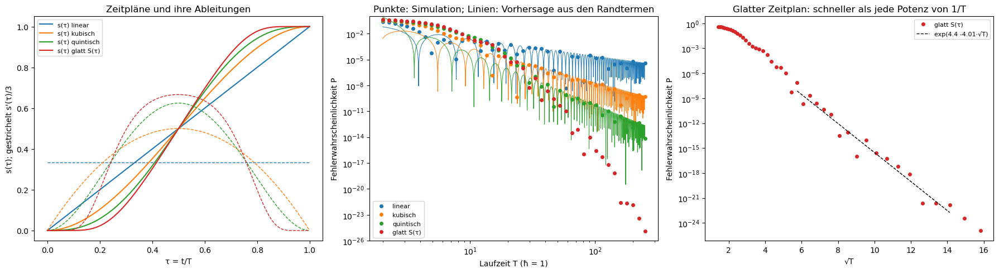

In [64]:
testfunctions.adiabatic_schedules()

**64. Grover-Minimumsuche auf Himmelblau**

Der Algorithmus von Dürr und Høyer findet das Minimum von N Werten mit etwa √N Abfragen statt N: Er sucht mit Grover wiederholt einen Wert unter der aktuellen Schwelle. Hier auf Himmelblau, diskretisiert auf ein Gitter mit N Punkten.

Die Zahl der Abfragen wächst wie √N, im Mittel 2.4√N bis 3.0√N; bei N = 2²⁰ sind es 2935 statt einer Million. Die Zahl der Schwellen wächst nur wie ln N, entlang der harmonischen Zahl H_N. Das gefundene Gitterminimum liegt jeweils bei einem der vier Minima von Himmelblau.

N = 2^ 6 =       64: Abfragen im Mittel     18.8 = 2.35·√N (90 % unter 4.38·√N);  Schwellen 4.62 (H_N = 4.74);  Gitterminimum f = 1.5035 bei (+3.571, -2.143)
N = 2^ 8 =      256: Abfragen im Mittel     44.5 = 2.78·√N (90 % unter 4.88·√N);  Schwellen 6.24 (H_N = 6.12);  Gitterminimum f = 0.9136 bei (+3.667, -1.667)
N = 2^10 =     1024: Abfragen im Mittel     86.2 = 2.69·√N (90 % unter 4.66·√N);  Schwellen 7.38 (H_N = 7.51);  Gitterminimum f = 0.2971 bei (-2.742, +3.065)
N = 2^12 =     4096: Abfragen im Mittel    191.5 = 2.99·√N (90 % unter 5.16·√N);  Schwellen 8.99 (H_N = 8.90);  Gitterminimum f = 0.0143 bei (+3.571, -1.825)
N = 2^14 =    16384: Abfragen im Mittel    376.0 = 2.94·√N (90 % unter 5.00·√N);  Schwellen 10.45 (H_N = 10.28);  Gitterminimum f = 0.0003 bei (+3.583, -1.850)


N = 2^16 =    65536: Abfragen im Mittel    757.3 = 2.96·√N (90 % unter 4.85·√N);  Schwellen 11.72 (H_N = 11.67);  Gitterminimum f = 0.0035 bei (+3.588, -1.863)
N = 2^18 =   262144: Abfragen im Mittel   1401.6 = 2.74·√N (90 % unter 4.53·√N);  Schwellen 12.90 (H_N = 13.05);  Gitterminimum f = 0.0016 bei (+3.004, +2.006)


N = 2^20 =  1048576: Abfragen im Mittel   2934.5 = 2.87·√N (90 % unter 4.73·√N);  Schwellen 14.93 (H_N = 14.44);  Gitterminimum f = 0.0005 bei (+3.583, -1.852)
Angepasster Exponent: Abfragen ∝ N^0.514


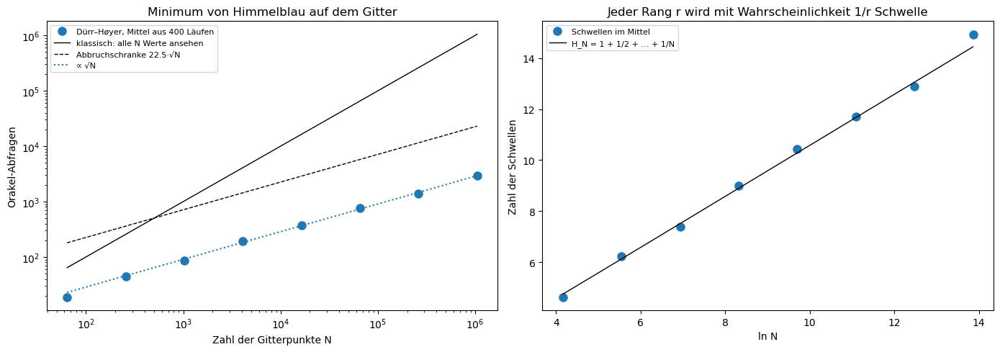

In [65]:
testfunctions.grover_minimum()

**65. VQE-Landschaften: ein Sinus pro Parameter und Barren Plateaus**

Beim Variational Quantum Eigensolver hängt die Energie von jedem Rotationswinkel wie ein Sinus ab. Daraus folgt die Parameter-Shift-Regel für exakte Gradienten; zufällige tiefe Schaltkreise haben aber flache Landschaften.

Drei Werte bestimmen den Sinus exakt (Abweichung 2.5·10⁻¹⁶), und der Parameter-Shift-Gradient stimmt mit der zentralen Differenz auf elf Stellen überein. Bei tiefen Schaltkreisen fällt die Varianz des Gradienten wie 2^(−n), um die Hälfte pro Qubit; bei n = 8 schwankt die Energie in einem Schnitt über zwei Parameter nur zwischen −0.03 und 0.03. Das ist ein Barren Plateau, die Easom-Ebene der Quantenoptimierung. Flache Schaltkreise haben das Problem nicht.

E(θ) aus drei Werten als a + b cos θ + c sin θ: größte Abweichung an 61 Stellen 2.5e-16
Gradient: Parameter-Shift -0.094038228181, zentrale Differenz (h = 1e−5) -0.094038228186


n =  2: Var E tief 2.03e-01 (Haar 1/(2^n+1) = 2.00e-01), Var ∂E tief 8.45e-02;  flach: Var E 2.20e-01, Var ∂E 8.98e-02


n =  4: Var E tief 6.03e-02 (Haar 1/(2^n+1) = 5.88e-02), Var ∂E tief 2.67e-02;  flach: Var E 1.68e-01, Var ∂E 8.86e-02


n =  6: Var E tief 1.67e-02 (Haar 1/(2^n+1) = 1.54e-02), Var ∂E tief 5.22e-03;  flach: Var E 1.80e-01, Var ∂E 8.49e-02


n =  8: Var E tief 4.93e-03 (Haar 1/(2^n+1) = 3.89e-03), Var ∂E tief 1.19e-03;  flach: Var E 1.82e-01, Var ∂E 8.82e-02


n = 10: Var E tief 1.25e-03 (Haar 1/(2^n+1) = 9.76e-04), Var ∂E tief 3.94e-04;  flach: Var E 1.37e-01, Var ∂E 1.19e-01
Var ∂E (tief) ∝ 2^(-1.02·n);  Rechenzeit 7.1 s
Schnitt durch die Landschaft, n = 2: E zwischen -0.866 und +0.920


Schnitt durch die Landschaft, n = 8: E zwischen -0.027 und +0.030


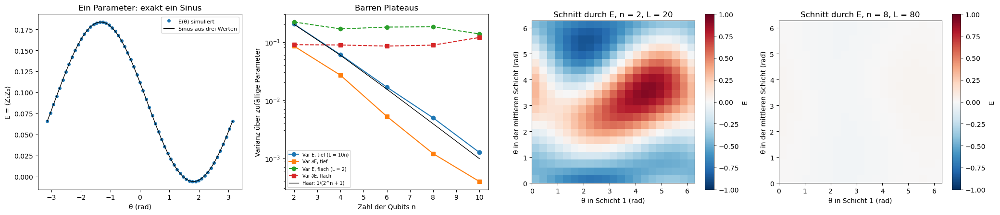

In [66]:
testfunctions.vqe_landscapes()